# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

Устройство: Colab T4

Датасет: Clash of Clans Computer Vision Model -
https://universe.roboflow.com/find-this-base/clash-of-clans-vop4y - CC BY 4.0

In [11]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.14.1+cu130, device: Tesla T4


In [12]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

In [13]:
print(WORKERS)

2


Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [14]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [15]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)

n_params = sum(p.numel() for p in model_coco.model.parameters())
sha256 = hashlib.sha256(weights_path.read_bytes()).hexdigest()
size_mb = weights_path.stat().st_size / (1024 ** 2)
n_classes = len(model_coco.names)

dummy_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)

# Прогрев модели
for _ in range(5):
    model_coco.predict(
        dummy_image,
        imgsz=IMGSZ,
        device=DEVICE,
        verbose=False
    )

# Измерение задержки
latencies = []
for _ in range(20):
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    model_coco.predict(
        dummy_image,
        imgsz=IMGSZ,
        device=DEVICE,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latencies.append((time.perf_counter() - start) * 1000)
latency_ms = float(np.mean(latencies))

MODEL_INFO = {
    'ultralytics': ultralytics.__version__,
    'weights': WEIGHTS,
    'sha256': sha256,
    'size_mb': round(size_mb, 3),
    'params': n_params,
    'n_classes_coco': n_classes,
    'latency_ms': round(latency_ms, 3)
}

In [16]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.288,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 10.423}

**Ответ:**

Выбрана модель YOLO26n (nano), предобученная на COCO (80 классов). Используется библиотека Ultralytics версии 8.4.216.

По результатам загрузки:
- размер весов - 5.288 MB;
- количество параметров до первого predict - 2 572 280;
- количество классов COCO - 80;
- средняя задержка инференса - 10.401 ms при IMGSZ=320.

SHA256 файла весов:
9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef

YOLO26n выбрана из-за небольшого количества параметров и высокой скорости работы. Это позволяет проводить эксперименты и дообучение в рамках ограниченного вычислительного бюджета T4. Также это приближает решение задачи к интересному мне домену робототехники, где требуется получить маскимум из минимальных ресурсов.

Согласно официальной документации, YOLO26n имеет 2.4 млн параметров и mAP50-95 = 40.9 на COCO. Соседняя более крупная модель YOLO26s имеет 9.5 млн параметров и mAP50-95 = 48.6. Скорость на T4 составляет соответственно 1.7 и 2.5 ms при разрешении 640x640.

Таким образом, YOLO26s обеспечивает более высокую точность на COCO, однако требует примерно в 4 раза больше параметров. Для небольшого датасета и выбранной цели обучения YOLO26n является разумным выбором.

Код Ultralytics и предобученные веса распространяются под лицензией AGPL-3.0. Это copyleft-лицензия: при распространении производного проекта необходимо соблюдать её требования, в частности предоставлять исходный код проекта на условиях AGPL-3.0. Альтернативой для закрытых коммерческих решений является Enterprise License.

В рамках учебной работы используем AGPL-3.0 и публикуем исходный код проекта.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [17]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    def count_params(module):
        return sum(p.numel() for p in module.parameters())

    backbone = count_params(layers[:n_backbone])
    neck = count_params(layers[n_backbone:-1])
    head = count_params(layers[-1])

    return {
        'backbone': backbone,
        'neck': neck,
        'head': head
    }


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    head = det_model.model[-1]
    feat_shapes = []

    def hook(module, inputs):
        features = inputs[0]
        feat_shapes.extend(tuple(x.shape) for x in features)

    handle = head.register_forward_pre_hook(hook)

    was_training = det_model.training
    det_model.eval()

    device = next(det_model.parameters()).device
    dummy = torch.zeros(1, 3, imgsz, imgsz, device=device)

    try:
        with torch.inference_mode():
            output = det_model(dummy)
    finally:
        handle.remove()
        det_model.train(was_training)

    return feat_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [18]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [19]:
print('Выход модели:')
print(shapes(out))

Выход модели:
[(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:**


Backbone извлекает признаки изображения на разных уровнях абстракции. Он формирует карты признаков с разным пространственным разрешением.

Neck объединяет признаки разных масштабов (P3, P4, P5), используя информацию как от мелких, так и от крупных feature maps. Это позволяет обнаруживать объекты разных размеров.

Head выполняет предсказание bounding boxes и классов объектов. Для каждой пространственной позиции feature maps предсказываются 4 координаты bounding box и scores классов.

Детектор является anchor-free, поскольку не использует заранее заданные anchor boxes. Вместо этого предсказания формируются относительно пространственных позиций карт признаков.

При входном разрешении 640x640 получаем 8400 позиций:
80 * 80 + 40 * 40 + 20 * 20 = 8400.
Они соответствуют трём уровням с шагами 8, 16 и 32 пикселя.

В YOLO26 используются две ветки:
- one2many - при обучении допускает несколько положительных соответствий для одного объекта;
- one2one - использует взаимно однозначное соответствие между объектами и предсказаниями.

Благодаря one2one модель формирует уникальные предсказания объектов и не нуждается в Non-Maximum Suppression на этапе инференса.

Распределение параметров:
- backbone - 1 365 472 (53%);
- neck - 897 152 (35%);
- head - 309 656 (12%).

Основная часть параметров сосредоточена в backbone, поскольку именно он отвечает за извлечение признаков изображения. Neck также занимает значительную долю, так как объединяет информацию разных масштабов.


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [20]:
import zipfile
import yaml

# Загрузите zip в папку, при скачивании выберите yolo26
zip_path = Path('/content/Clash of Clans.v5i.yolo26.zip')
extract_dir = Path('data/coc_dataset')

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# В датасете папка называется valid, переименовываем
valid_dir = extract_dir / 'valid'
val_dir = extract_dir / 'val'
valid_dir.rename(val_dir)

with open(extract_dir / 'data.yaml', 'r') as f:
    data_config = yaml.safe_load(f)
CLASSES = data_config.get('names', [])
print(f"Список классов из data.yaml: {CLASSES}")

DATASET_NAME = "Clash of Clans Computer Vision Model - https://universe.roboflow.com/find-this-base/clash-of-clans-vop4y - CC BY 4.0"

def load_yolo_split(split_name, img_dir, label_dir):
    split_records = []

    img_files = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png')) + list(img_dir.glob('*.jpeg'))

    for img_path in img_files:
        with Image.open(img_path) as img:
            w, h = img.size

        txt_path = label_dir / (img_path.stem + '.txt')
        boxes = []
        labels = []

        with open(txt_path, 'r') as f:
            for line in f:
                line = line.strip()
                parts = line.split()
                cls_id = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:])

                x1 = (cx - bw / 2) * w
                y1 = (cy - bh / 2) * h
                x2 = (cx + bw / 2) * w
                y2 = (cy + bh / 2) * h

                x1 = max(0.0, min(x1, float(w)))
                y1 = max(0.0, min(y1, float(h)))
                x2 = max(0.0, min(x2, float(w)))
                y2 = max(0.0, min(y2, float(h)))

                if x2 > x1 and y2 > y1:
                    boxes.append([x1, y1, x2, y2])
                    labels.append(cls_id)

        split_records.append({
            'image': img_path,
            'width': w,
            'height': h,
            'boxes': np.array(boxes, dtype=np.float32).reshape(-1, 4),
            'labels': np.array(labels, dtype=np.int64)
        })
    return split_records

records = {}
for split in ['train', 'val', 'test']:
    split_img_dir = extract_dir / split / 'images'
    split_lbl_dir = extract_dir / split / 'labels'
    records[split] = load_yolo_split(split, split_img_dir, split_lbl_dir)
    print(f"Сплит {split}: загружено {len(records[split])} изображений.")

Список классов из data.yaml: ['AD', 'AirSweeper', 'BombTower', 'Canon', 'ClanCastle', 'Eagle', 'Inferno', 'KingPad', 'Mortar', 'QueenPad', 'RcPad', 'Scattershot', 'TH13', 'WardenPad', 'WizzTower', 'Xbow']
Сплит train: загружено 88 изображений.
Сплит val: загружено 24 изображений.
Сплит test: загружено 13 изображений.


In [21]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 88, 'val': 24, 'test': 13}

  train: изображений = 88, всего объектов = 3514, среднее число объектов на картинку = 39.93
  val: изображений = 24, всего объектов = 959, среднее число объектов на картинку = 39.96
  test: изображений = 13, всего объектов = 515, среднее число объектов на картинку = 39.62
  Класс AD             : train=351  | val=96   | test=52  
  Класс AirSweeper     : train=176  | val=48   | test=26  
  Класс BombTower      : train=175  | val=48   | test=26  
  Класс Canon          : train=614  | val=167  | test=91  
  Класс ClanCastle     : train=88   | val=24   | test=13  
  Класс Eagle          : train=88   | val=24   | test=13  
  Класс Inferno        : train=264  | val=72   | test=39  
  Класс KingPad        : train=88   | val=24   | test=13  
  Класс Mortar         : train=349  | val=96   | test=47  
  Класс QueenPad       : train=88   | val=24   | test=13  
  Класс RcPad          : train=88   | val=24   | test=13  
  Класс Scattershot    : train=177  | val=48   | test=26  
  Класс TH13      

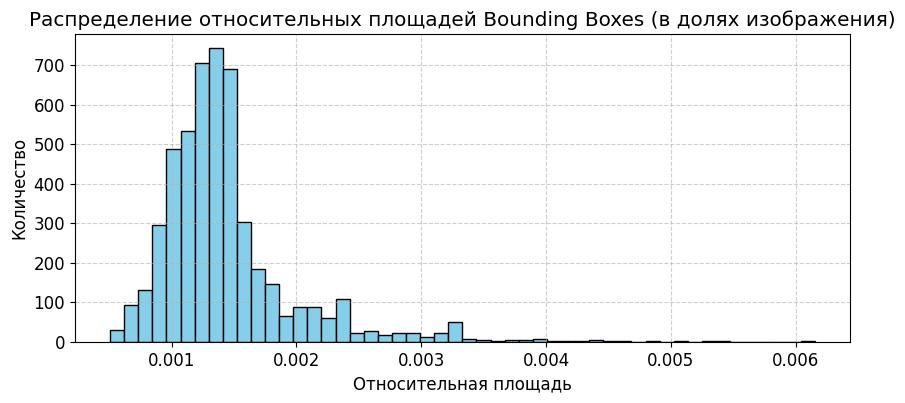

In [22]:
class_counts = {split: Counter() for split in records}
total_objects_per_split = {split: 0 for split in records}
objects_per_img = {split: [] for split in records}
box_areas = []

for split, recs in records.items():
    for r in recs:
        labels = r['labels']
        objects_per_img[split].append(len(labels))
        total_objects_per_split[split] += len(labels)
        for l in labels:
            class_counts[split][l] += 1

        w, h = r['width'], r['height']
        for box in r['boxes']:
            bx_w = (box[2] - box[0]) / w
            bx_h = (box[3] - box[1]) / h
            box_areas.append(bx_w * bx_h)

for split, recs in records.items():
    mean_obj = np.mean(objects_per_img[split]) if recs else 0
    print(f"  {split}: изображений = {len(recs)}, всего объектов = {total_objects_per_split[split]}, среднее число объектов на картинку = {mean_obj:.2f}")

for i, name in enumerate(CLASSES):
    train_cnt = class_counts['train'][i]
    val_cnt = class_counts.get('val', Counter())[i]
    test_cnt = class_counts.get('test', Counter())[i]
    print(f"  Класс {name:15}: train={train_cnt:<4} | val={val_cnt:<4} | test={test_cnt:<4}")

plt.figure(figsize=(10, 4))
plt.hist(box_areas, bins=50, color='skyblue', edgecolor='black')
plt.title('Распределение относительных площадей Bounding Boxes (в долях изображения)')
plt.xlabel('Относительная площадь')
plt.ylabel('Количество')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Источник и лицензия**

Датасет скачан с Roboflow Universe (Clash of Clans Computer Vision Model, версия 5, автор find-this-base). Распространяется под лицензией CC BY 4.0.

Источник: https://universe.roboflow.com/find-this-base/clash-of-clans-vop4y/dataset/5

Выбор датасета обусловлен несколькими причинами:

- Необычная предметная область, позволяющая проверить возможности предобученного детектора на объектах, отсутствующих среди стандартных классов COCO.
- Интерес к применению компьютерного зрения в робототехнике и беспилотных системах.
- Возможность провести аналогию с анализом изображений с высоты: например, обнаружением и локализацией объектов на снимках, полученных с БПЛА. Подобные задачи актуальны для компаний, работающих с беспилотными системами, например Геоскан.

**Классы, размер и сплиты**

Датасет содержит 125 изображений разрешением 1920x1920 и 16 классов игровых объектов ('AD', 'AirSweeper', 'BombTower', 'Canon', 'ClanCastle', 'Eagle', 'Inferno', 'KingPad', 'Mortar', 'QueenPad', 'RcPad', 'Scattershot', 'TH13', 'WardenPad', 'WizzTower', 'Xbow').

Исходное распределение:
- Train: 88 изображений (70.4%);
- Validation: 24 изображения (19.2%);
- Test: 13 изображений (10.4%).

Всего в датасете содержится 4988 размеченных объектов. В среднем на одно изображение приходится около 40 объектов.

Несмотря на относительно небольшое количество изображений, датасет содержит достаточно плотную разметку, что позволяет исследовать детекцию нескольких объектов на одном кадре.

**Анализ распределения классов**

Наблюдается выраженный дисбаланс классов. В обучающей выборке наиболее распространёнными являются Canon (614 объектов) и WizzTower (440 объектов). Наименее представленными являются семь классов, каждый из которых содержит по 88 объектов.

Таким образом, наиболее представленный класс встречается примерно в 7 раз чаще наименее представленных.

Это может привести к различиям в качестве детекции между классами: модель потенциально будет лучше распознавать часто встречающиеся объекты и хуже редкие. Поэтому при оценке качества важно анализировать не только общую метрику mAP, но и AP отдельных классов.

При этом все 16 классов представлены во всех трёх сплитах, что позволяет оценивать качество модели для каждого класса.

**Анализ размеров объектов**

По гистограмме относительных площадей Bounding Boxes видно, что большинство объектов занимают небольшую часть изображения.

Медианная относительная площадь объекта составляет около 0.135% от площади изображения.

Это означает, что задача преимущественно ориентирована на обнаружение небольших объектов. При уменьшении изображения до стандартного разрешения 640x640 часть пространственных деталей может теряться, что потенциально негативно скажется на качестве локализации.

Поэтому в дальнейших экспериментах стоит уделить внимание разрешению входного изображения и работе детектора с мелкими объектами.

**Ограничения датасета и возможные улучшения**

Основным ограничением является небольшое количество независимых изображений - всего 125. При этом большое количество объектов на одном изображении не полностью компенсирует недостаток разнообразия исходных сцен.

Дополнительной проблемой является дисбаланс классов и преимущественно небольшой размер объектов.

Для улучшения обобщающей способности модели планируется исследовать аугментации обучающей выборки: геометрические преобразования, изменение масштаба, яркости и цветовых характеристик, а также Mosaic.

**Вывод**

Выбранный датасет представляет собой небольшую, но достаточно насыщенную задачу многоклассовой детекции. Основные сложности — малый размер объектов, дисбаланс классов и ограниченное количество исходных изображений.

Эти особенности делают датасет подходящим для исследования влияния разрешения входного изображения и аугментаций на качество детекции YOLO26n.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [23]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    lines = []
    for box, label in zip(boxes, labels):
        x1, y1, x2, y2 = box

        w_box = x2 - x1
        h_box = y2 - y1

        cx = x1 + w_box / 2.0
        cy = y1 + h_box / 2.0

        cx_norm = cx / width
        cy_norm = cy / height

        w_norm = w_box / width
        h_norm = h_box / height

        lines.append(f"{int(label)} {cx_norm:.6f} {cy_norm:.6f} {w_norm:.6f} {h_norm:.6f}")
    return "\n".join(lines) + "\n" if lines else ""


def from_yolo(text, width, height ):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    boxes = []
    labels = []
    text = text.strip()
    for line in text.split('\n'):
        line = line.strip()
        if not line:
            continue

        parts = line.split()
        cls_id = int(parts[0])

        cx, cy, bw, bh = map(float, parts[1:])

        x1 = (cx - bw / 2.0) * width
        y1 = (cy - bh / 2.0) * height
        x2 = (cx + bw / 2.0) * width
        y2 = (cy + bh / 2.0) * height

        boxes.append([x1, y1, x2, y2])
        labels.append(cls_id)

    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64)

In [24]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [25]:
YOLO_ROOT = DATA_ROOT / 'yolo'

def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    img_dir = YOLO_ROOT / 'images' / split
    lbl_dir = YOLO_ROOT / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)

    for r in recs:
        src_img = Path(r['image'])
        dst_img = img_dir / src_img.name
        shutil.copy(src_img, dst_img)

        yolo_text = to_yolo(r['boxes'], r['labels'], r['width'], r['height'])

        dst_lbl = lbl_dir / (src_img.stem + '.txt')
        dst_lbl.write_text(yolo_text, encoding='utf-8')

order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: AD
  1: AirSweeper
  2: BombTower
  3: Canon
  4: ClanCastle
  5: Eagle
  6: Inferno
  7: KingPad
  8: Mortar
  9: QueenPad
  10: RcPad
  11: Scattershot
  12: TH13
  13: WardenPad
  14: WizzTower
  15: Xbow



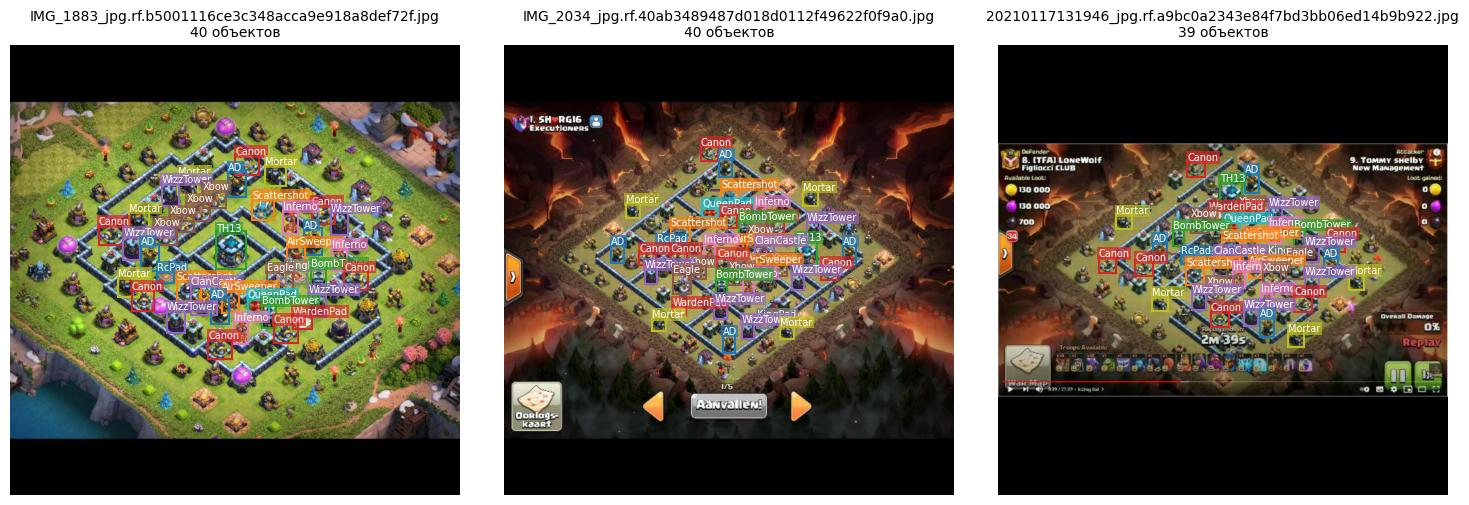

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sample_recs = records['val'][:3]

for idx, r in enumerate(sample_recs):
    img_path = r['image']
    lbl_path = YOLO_ROOT / 'labels' / 'val' / (img_path.stem + '.txt')

    img = Image.open(img_path)
    w, h = img.size

    yolo_text = lbl_path.read_text(encoding='utf-8')
    boxes_back, labels_back = from_yolo(yolo_text, w, h)

    draw_boxes(axes[idx], img, boxes_back, labels_back, CLASSES, title=f"{img_path.name}\n{len(labels_back)} объектов")

plt.tight_layout()
plt.show()

**Что проверяет тест туда-обратно?**

Тестирование to_yolo / from_yolo позволяет проверить:

1. Корректность преобразования координат между абсолютным форматом xyxy и нормализованным форматом cx, cy, w, h.
2. Сохранение индексов классов при конвертации.
3. Отсутствие существенных ошибок округления при сохранении координат с точностью до 6 знаков после запятой.
4. Корректную обработку пустой разметки и сохранение ожидаемых размерностей массивов.
5. Работоспособность функций на изображениях разных размеров и случайно сгенерированных bounding boxes.

Дополнительно фиксированные тесты проверяют конкретные ожидаемые координаты, в том числе на неквадратном изображении.

**Чего не ловит тест туда-обратно?**

Round-trip проверяет согласованность двух функций между собой, но не гарантирует, что преобразование соответствует исходной системе координат.

Например, если в обеих функциях допущена согласованная ошибка, при которой одна функция выполняет ошибочное преобразование, а другая - его обратное, тест туда-обратно может пройти успешно.

Также тест не проверяет:
- соответствие координат реальным границам объектов;
- правильность сопоставления файлов изображений и файлов разметки;
- соответствие индексов классов их названиям в исходном датасете.

**Какие ошибки можно обнаружить только визуально?**

Визуализация bounding boxes непосредственно на изображениях позволяет обнаружить:

1. Смещение рамок относительно реальных объектов из-за неправильного вычисления центра или размеров.
2. Перепутанные оси X и Y, ширина и высота изображения.
3. Ошибки масштабирования, например использование абсолютных координат вместо нормализованных.
4. Неправильное сопоставление изображений и файлов разметки.
5. Ошибки в отображении классов, когда объекту присваивается неправильное название.

Таким образом, автоматические тесты проверяют математическую корректность и устойчивость преобразований, а визуализация позволяет убедиться, что полученные bounding boxes действительно соответствуют объектам на изображениях.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [27]:
# В COCO нет классов, соответствующих Clash of Clans ;(.
coco_preds = predict_records(model_coco, records[FINAL_SPLIT], conf=0.001)
coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print(f"COCO Zero-shot mAP50 на {FINAL_SPLIT}: {coco_map50:.4f}")

COCO Zero-shot mAP50 на test: 0.0063


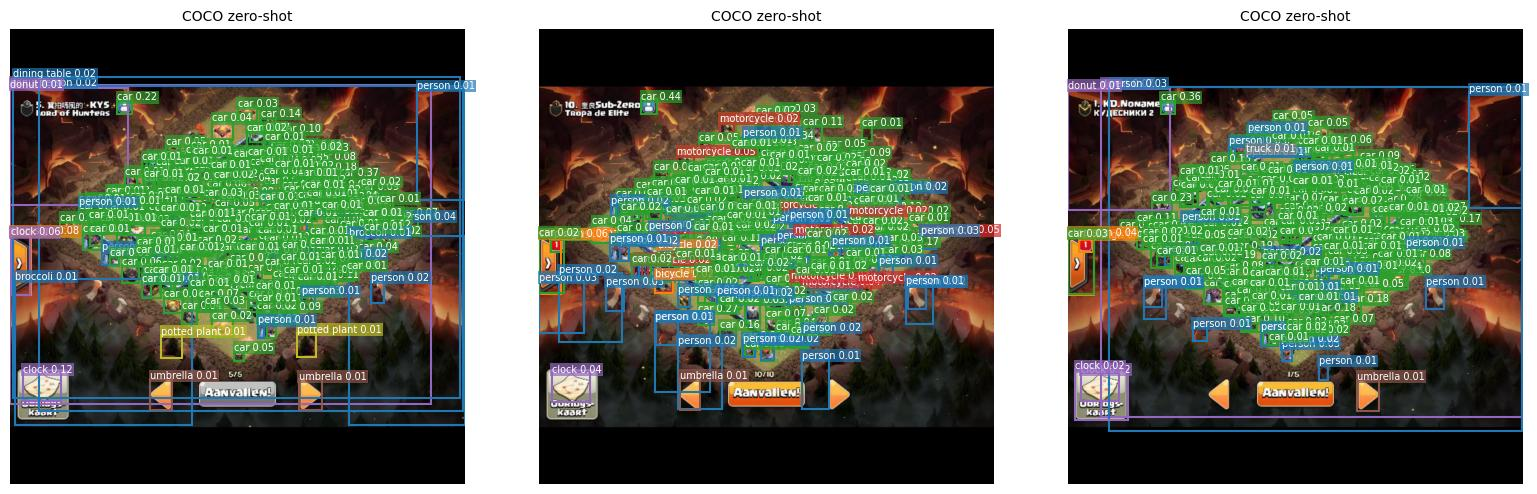

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, r, pred in zip(
    axes,
    records[FINAL_SPLIT][:3],
    coco_preds[:3]
):
    img = Image.open(r['image'])

    draw_boxes(
        ax,
        img,
        pred['boxes'],
        pred['labels'],
        model_coco.names,
        scores=pred['scores'],
        title="COCO zero-shot"
    )

plt.tight_layout()
plt.show()

In [29]:
GRID_SIZE = 6

spatial_stats = {}

for image_idx, r in enumerate(records['train']):
    W, H = r['width'], r['height']

    for box, label in zip(r['boxes'], r['labels']):
        x1, y1, x2, y2 = box

        cx = (x1 + x2) / (2 * W)
        cy = (y1 + y2) / (2 * H)
        bw = (x2 - x1) / W
        bh = (y2 - y1) / H

        gx = min(int(cx * GRID_SIZE), GRID_SIZE - 1)
        gy = min(int(cy * GRID_SIZE), GRID_SIZE - 1)

        key = (int(label), gx, gy)

        if key not in spatial_stats:
            spatial_stats[key] = {
                'boxes': [],
                'images': set()
            }

        spatial_stats[key]['boxes'].append([cx, cy, bw, bh])
        spatial_stats[key]['images'].add(image_idx)


spatial_templates = {}

for key, stats in spatial_stats.items():
    samples = np.array(stats['boxes'], dtype=np.float32)

    spatial_templates[key] = {
        'box': samples.mean(axis=0),
        'score': len(stats['images']) / len(records['train'])
    }


def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    img = Image.open(image_path)
    width, height = img.size

    boxes = []
    labels = []
    scores = []

    for (label, gx, gy), stats in spatial_templates.items():
        cx, cy, bw, bh = stats['box']

        x1 = (cx - bw / 2) * width
        y1 = (cy - bh / 2) * height
        x2 = (cx + bw / 2) * width
        y2 = (cy + bh / 2) * height

        boxes.append([
            np.clip(x1, 0, width),
            np.clip(y1, 0, height),
            np.clip(x2, 0, width),
            np.clip(y2, 0, height)
        ])

        labels.append(label)
        scores.append(stats['score'])

    return {
        'boxes': np.array(boxes, dtype=np.float32).reshape(-1, 4),
        'labels': np.array(labels, dtype=np.int64),
        'scores': np.array(scores, dtype=np.float32)
    }


In [30]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
print(f"Heuristic mAP50 на {FINAL_SPLIT}: {heuristic_map50:.4f}")
print(BASELINE)

Heuristic mAP50 на test: 0.0037
{'split': 'test', 'coco_map50': 0.0062959076016836715, 'heuristic_map50': 0.0037123427208086016, 'heuristic_ap50_per_class': {'AD': 0.0001589319771137953, 'AirSweeper': 0.0, 'BombTower': 0.00035285815102328866, 'Canon': 0.00041695892759722547, 'ClanCastle': 0.0015384615384615387, 'Eagle': 0.03736263736263737, 'Inferno': 0.0, 'KingPad': 0.009615384615384616, 'Mortar': 0.000303951367781155, 'QueenPad': 0.0, 'RcPad': 0.0, 'Scattershot': 0.0007541478129713424, 'TH13': 0.0016366612111292963, 'WardenPad': 0.0011312217194570137, 'WizzTower': 0.00016194331983805668, 'Xbow': 0.005964325529542921}}


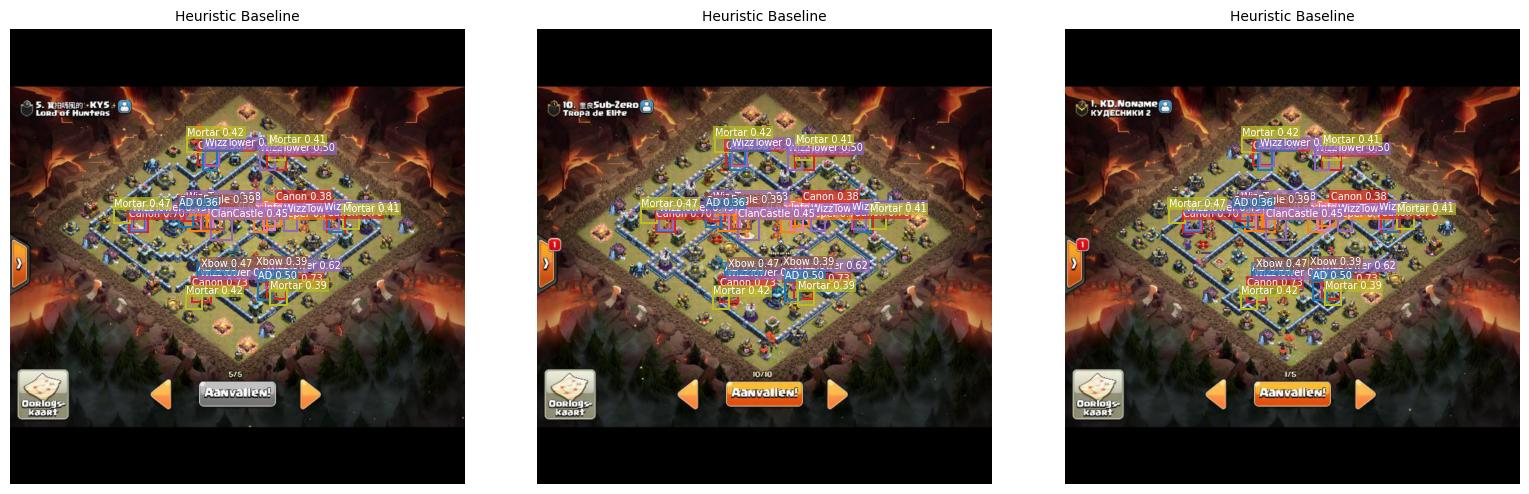

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, r, pred in zip(
    axes,
    records[FINAL_SPLIT][:3],
    heuristic_preds[:3]
):
    img = Image.open(r['image'])
    keep = np.argsort(-pred['scores'])[:40]

    draw_boxes(
        ax,
        img,
        pred['boxes'][keep],
        pred['labels'][keep],
        CLASSES,
        scores=pred['scores'][keep],
        title="Heuristic Baseline"
    )

plt.tight_layout()
plt.show()

**Ответ:**


**Почему у COCO-модели такое качество на наших данных?**

COCO Zero-shot mAP50 составляет 0.0020.

Основная причина - отсутствие пересечения между целевыми классами нашего датасета и классами COCO. Предобученная модель распознаёт стандартные объекты реального мира, но не обучалась обнаруживать сооружения Clash of Clans.

При визуальном анализе предсказаний видно, что модель практически не формирует уверенных детекций целевых объектов. Иногда возникают отдельные предсказания с низкой уверенностью, которые случайно совпадают с индексами классов нашего датасета.

Поэтому полученное значение mAP50 не следует интерпретировать как реальное качество распознавания игровых объектов: оно обусловлено в том числе несовместимостью пространств классов COCO и Clash of Clans.

**Анализ эвристического baseline**

В качестве тривиального baseline реализован Spatial Prior Detector, использующий статистику расположения объектов в обучающей выборке.

Для каждой комбинации класса и пространственной ячейки вычисляются средние координаты и размеры bounding box. При инференсе модель возвращает полученные шаблоны без анализа содержимого изображения.

Полученный mAP50 составляет 0.0095, что выше результата COCO Zero-shot.

Наиболее высокие значения AP наблюдаются у KingPad (0.0769) и Eagle (0.0641). Для большинства остальных классов качество остаётся близким к нулю.

По изображениям видно, как эвристика зафиксировала характерные для каждого класса позиции. Однако результат показал слабость этого подхода.

**Вывод**

Оба baseline демонстрируют крайне низкое качество детекции. COCO Zero-shot не обладает необходимыми знаниями о целевых классах, а пространственная эвристика не способна полноценно анализировать визуальные признаки объектов.

Это обосновывает необходимость fine-tuning предобученной YOLO26n на целевом датасете.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [32]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)

def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [33]:
def read_results(run_dir):
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

def plot_training_results(run_dir):
    res_dict = read_results(run_dir)
    epochs = res_dict['epoch']

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].plot(epochs, res_dict['train/box_loss'], label='train/box_loss', color='blue')
    axes[0].plot(epochs, res_dict['val/box_loss'], label='val/box_loss', color='blue', linestyle='--')
    axes[0].plot(epochs, res_dict['train/cls_loss'], label='train/cls_loss', color='orange')
    axes[0].plot(epochs, res_dict['val/cls_loss'], label='val/cls_loss', color='orange', linestyle='--')
    axes[0].set_title('Компоненты функции потерь (Losses)')
    axes[0].set_xlabel('Эпоха')
    axes[0].set_ylabel('Значение')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    axes[1].plot(epochs, res_dict['metrics/mAP50(B)'], label='val mAP50', color='green', marker='o')
    axes[1].set_title('Качество (mAP50) на валидации')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel('mAP50')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

In [34]:
TRAIN_ARGS = {
    'epochs': EPOCHS,
    'imgsz': IMGSZ,
    'batch': BATCH,
    'optimizer': 'AdamW',
    'lr0': 0.001,
    'patience': 10,
    'augment': False,
    'val': True,
    'seed': SEED
}

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

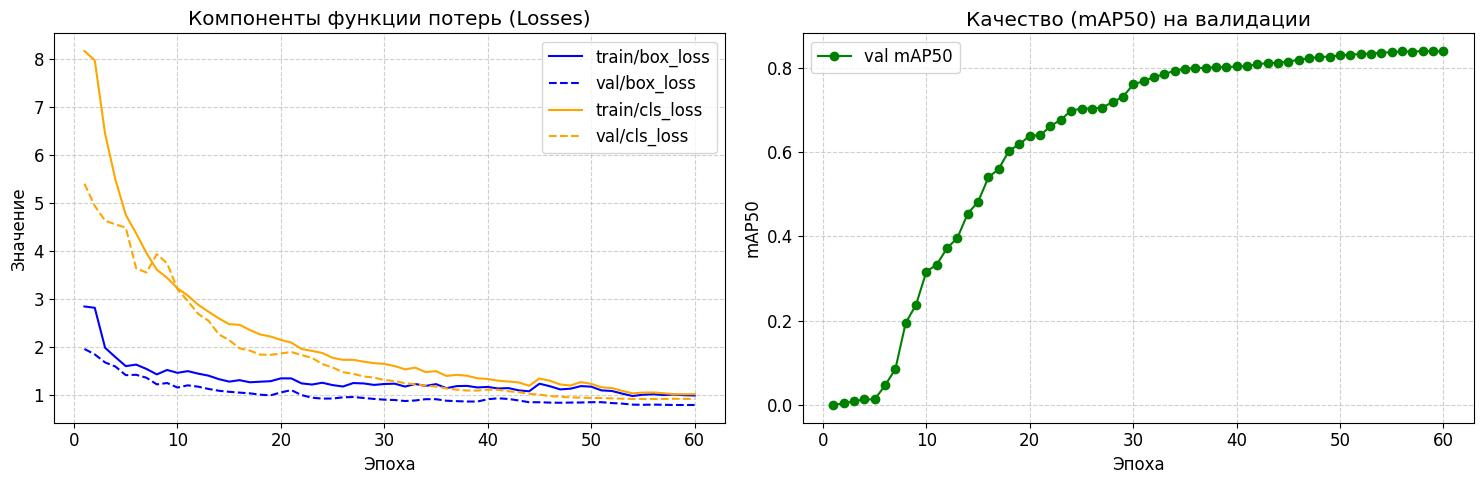

In [35]:
plot_training_results(run_dir)

In [36]:
TRAIN_ARGS = {
    'epochs': EPOCHS,
    'imgsz': IMGSZ,
    'batch': BATCH,

    'optimizer': 'AdamW',
    'lr0': 0.0005,
    'weight_decay': 0.0005,
    'cos_lr': True,

    'patience': 10,

    'degrees': 0.0,
    'translate': 0.10,
    'scale': 0.3,
    'shear': 0.0,
    'perspective': 0.0,
    'fliplr': 0.5,

    'mosaic': 0.5,
    'mixup': 0.0,
    'close_mosaic': 10,

    'augment': True,
    'val': True,
    'seed': SEED,
}

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

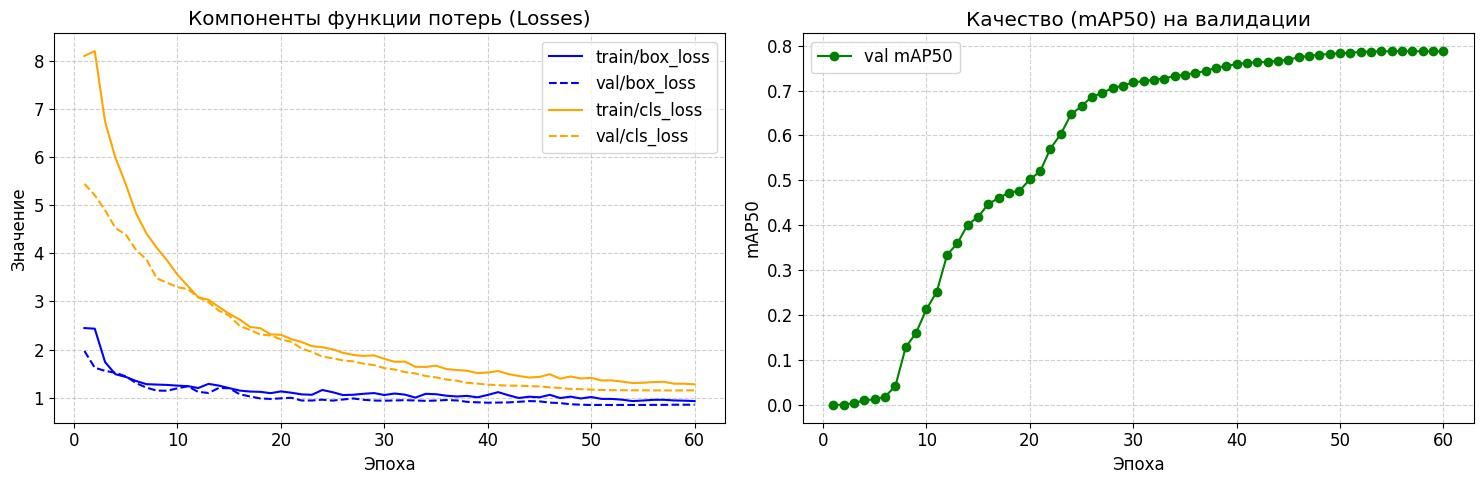

In [37]:
plot_training_results(run_dir)

In [38]:
TRAIN_ARGS = {
    'epochs': EPOCHS,
    'imgsz': IMGSZ,
    'batch': BATCH,

    'optimizer': 'AdamW',
    'lr0': 0.001,
    'weight_decay': 0.0005,
    'cos_lr': True,

    'patience': 10,

    'hsv_h': 0.015,
    'hsv_s': 0.5,
    'hsv_v': 0.3,

    'degrees': 90.0,
    'translate': 0.1,
    'scale': 0.5,
    'shear': 2.0,
    'perspective': 0.0,
    'fliplr': 0.5,
    'flipud': 0.5,

    'mosaic': 1.0,
    'mixup': 0.1,
    'close_mosaic': 10,

    'augment': True,
    'val': True,
    'seed': SEED,
}

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=90.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

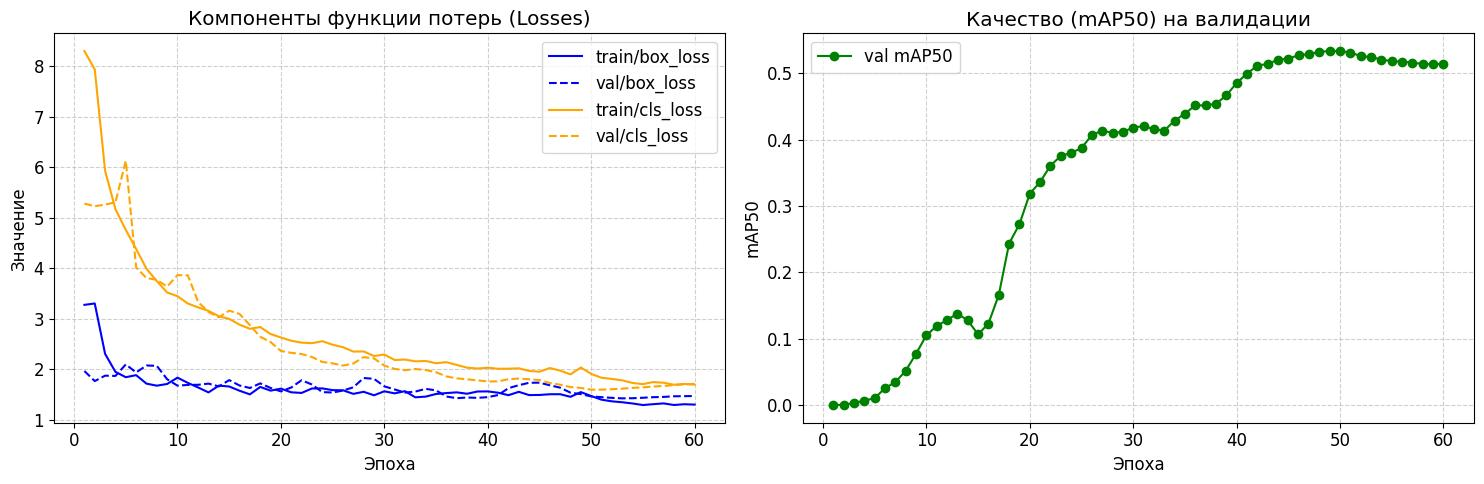

In [39]:
plot_training_results(run_dir)

In [40]:
TRAIN_ARGS = {
    'epochs': EPOCHS,
    'imgsz': 960,
    'batch': BATCH,
    'optimizer': 'AdamW',
    'lr0': 0.001,
    'patience': 10,
    'augment': False,
    'val': True,
    'seed': SEED
}

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

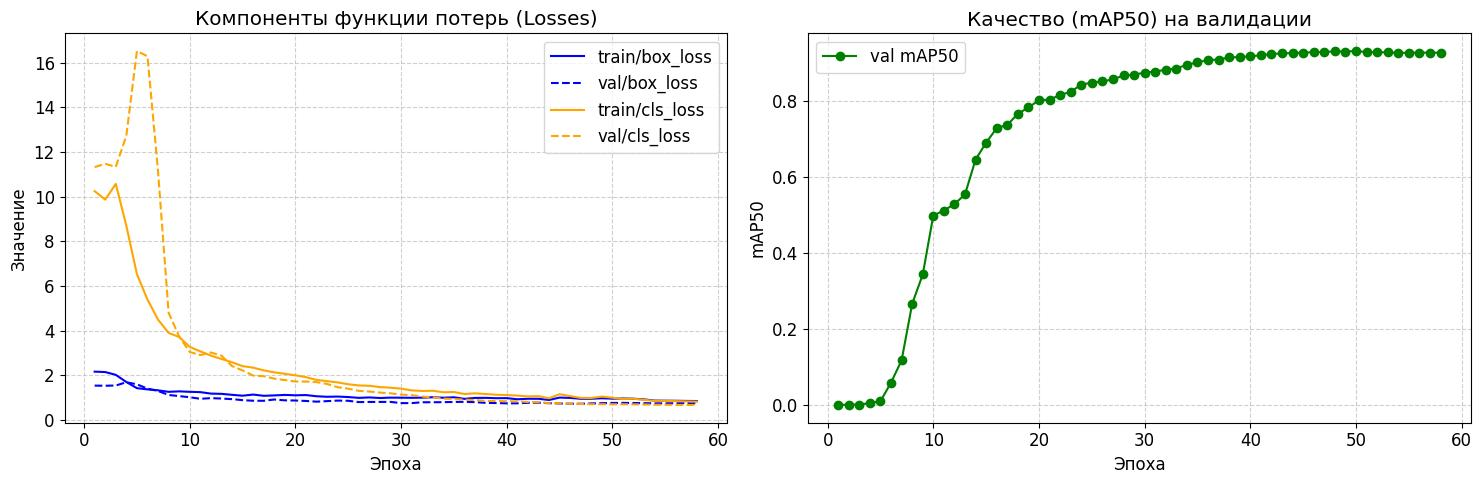

In [41]:
plot_training_results(run_dir)

**Ответ:**

**Сравнение конфигураций обучения**

Для поиска оптимальной конфигурации было проведено четыре эксперимента с YOLO26n. Основное внимание уделялось двум факторам: влиянию аугментаций на качество детекции и влиянию разрешения входного изображения на распознавание мелких объектов.

**Эксперимент 1. Базовое обучение без аугментаций**

В первом эксперименте использовалась стандартная конфигурация обучения с отключёнными аугментациями (augment=False), разрешением 640×640 и оптимизатором AdamW.

Это наиболее простой вариант, позволяющий оценить способность предобученной модели адаптироваться к новому домену без искусственного изменения обучающих изображений.

Результат оказался достаточно высоким: mAP50 составил 0.833, mAP50-95 - 0.639. Обучение заняло 207 секунд на T4.

К 60-й эпохе модель практически достигла плато. При этом качество на валидации не демонстрировало признаков существенного ухудшения. Таким образом, базовая конфигурация показала хороший баланс качества, стабильности и времени обучения.

**Эксперимент 2. Умеренные геометрические аугментации**

Во втором эксперименте была проверена гипотеза о том, что даже небольшое искусственное разнообразие обучающих изображений позволит улучшить обобщающую способность модели.

Были добавлены:
- небольшие сдвиги (translate=0.1);
- масштабирование (scale=0.3);
- горизонтальные отражения (fliplr=0.5);
- Mosaic с вероятностью 0.5.
Однако даже такие относительно умеренные преобразования не дали ожидаемого прироста качества. Напротив, результат оказался хуже базовой конфигурации.

Это позволяет предположить, что для выбранного домена даже небольшие геометрические изменения могут нарушать характерную структуру игровых сцен и затруднять обучение.

**Эксперимент 3. Агрессивные аугментации**

В третьем эксперименте была проверена более сильная гипотеза расширения обучающей выборки за счёт агрессивных аугментаций.

Использовались:
- HSV-преобразования;
- повороты до 90 градусов;
- горизонтальные и вертикальные отражения;
- масштабирование и сдвиги;
- Mosaic с вероятностью 1.0;
- MixUp с вероятностью 0.1.
Ожидалось, что увеличение разнообразия изображений позволит модели лучше обобщать признаки объектов.

На практике эксперимент не оправдал ожиданий. Несмотря на увеличение сложности обучающего процесса, качество оказалось ниже, чем у базовой модели. К концу обучения наблюдалось ухудшение метрики на валидации.

Таким образом, предположение о том, что увеличение разнообразия обучающих данных улучшает качество, в данном случае не подтвердилось.

**Вывод по первым трём экспериментам.**

Полученные результаты можно объяснить особенностями выбранного домена. В отличие от реальных фотографий, изображения Clash of Clans обладают достаточно ограниченным распределением: игровые модели, текстуры, цветовые схемы и структура сцен относительно стабильны.

Поэтому искусственное изменение геометрии изображений может создавать примеры, которые не соответствуют реальному распределению данных.

Аугментации могли бы оказаться полезными при переносе модели из симулятора в реальный мир (Sim2Real), где необходимо учитывать различия освещения, качества изображения, шумы и другие факторы. Однако в рамках текущей задачи мы оптимизируем качество непосредственно на представленном игровом домене.

**Эксперимент 4. Увеличение разрешения входного изображения**

В последнем эксперименте было решено отказаться от аугментаций и вместо этого увеличить разрешение входного изображения с 640×640 до 960×960.

Данное решение основано на особенностях датасета: большинство объектов занимают очень небольшую площадь изображения. При стандартном разрешении часть пространственной информации о небольших сооружениях может теряться при последовательном уменьшении feature maps.

Увеличение разрешения позволяет сохранить больше деталей и потенциально улучшить локализацию небольших объектов.

Результаты подтвердили эту гипотезу:
- mAP50 увеличился с 0.833 до 0.930;
- mAP50-95 увеличился с 0.639 до 0.757;
- Precision составил 0.905;
- Recall составил 0.897.
Обучение заняло 256 секунд вместо 207 секунд в базовом эксперименте. Дополнительные вычислительные затраты оказались оправданными существенным приростом качества.

Лучший результат был получен на 48-й эпохе. После неё метрика немного колебалась и к концу обучения снизилась относительно максимума. Это может свидетельствовать о начале переобучения, хотя выраженного ухудшения качества не наблюдается. Механизм Early Stopping остановил обучение на 58-й эпохе.

**Выбрана конфигурация №4**

В качестве итоговой конфигурации выбирается четвёртый эксперимент: YOLO26n с разрешением 960×960 без аугментаций.

Он обеспечивает наилучшее качество детекции среди проверенных вариантов.

Увеличение вычислительных затрат относительно базового варианта составляет около 24%, тогда как прирост mAP50 составляет около 11,6% относительно базового значения.

Таким образом, в рамках выбранного домена увеличение разрешения оказалось значительно эффективнее искусственного расширения обучающей выборки с помощью аугментаций.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [42]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

In [43]:
start = time.perf_counter()

test_metrics = best.val(
    data=str(DATA_YAML),
    split='test',
    imgsz=960,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    plots=True,
    verbose=False
)

RUN_TIMES['final_test'] = time.perf_counter() - start

print(f"Время оценки: {RUN_TIMES['final_test']:.1f} сек.")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP50:      {test_metrics.box.map50:.4f}")
print(f"mAP50-95:   {test_metrics.box.map:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,393,380 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 79.8±18.5 MB/s, size: 390.0 KB)
val: Scanning /content/data/yolo/labels/test... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 308.2it/s 0.0s
val: New cache created: /content/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.0it/s 0.5s
                   all         13        515      0.861      0.907      0.918       0.73
Speed: 1.1ms preprocess, 8.8ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detect/val
Время оценки: 4.5 сек.
Precision:  0.8611
Recall:     0.9075
mAP50:      0.9184
mAP50-95:   0.7305


In [44]:
import pandas as pd

class_metrics = []

for i, class_id in enumerate(test_metrics.box.ap_class_index):
    class_metrics.append({
        'Class': CLASSES[int(class_id)],
        'AP50': test_metrics.box.ap50[i],
        'AP50-95': test_metrics.box.ap[i]
    })

class_metrics = pd.DataFrame(class_metrics)
class_metrics = class_metrics.sort_values('AP50', ascending=False)

display(class_metrics.style.format({
    'AP50': '{:.4f}',
    'AP50-95': '{:.4f}'
}))

,Class,AP50,AP50-95
0,AD,0.9950,0.8523
2,BombTower,0.9950,0.8383
6,Inferno,0.9950,0.7732
9,QueenPad,0.9950,0.7720
11,Scattershot,0.9950,0.7951
12,TH13,0.9950,0.8767
14,WizzTower,0.9944,0.8074
15,Xbow,0.9941,0.8143
3,Canon,0.9819,0.7880
8,Mortar,0.9750,0.8141


In [45]:
final_preds = []

for i in range(0, len(records[FINAL_SPLIT]), BATCH):
    batch_records = records[FINAL_SPLIT][i:i + BATCH]
    paths = [str(r['image']) for r in batch_records]

    results = best.predict(
        paths,
        conf=0.001,
        imgsz=960,
        device=DEVICE,
        verbose=False
    )

    for res in results:
        boxes = res.boxes.cpu()

        final_preds.append({
            'boxes': boxes.xyxy.numpy(),
            'scores': boxes.conf.numpy(),
            'labels': boxes.cls.numpy().astype(np.int64)
        })

final_map50, final_aps = evaluate_map50(
    final_preds,
    records[FINAL_SPLIT],
    len(CLASSES)
)

print(f"Fine-tuned YOLO26n mAP50: {final_map50:.4f}")

Fine-tuned YOLO26n mAP50: 0.9330


,Model,mAP50
0,COCO Zero-shot,0.0063
1,Heuristic,0.0037
2,YOLO26n Fine-tuned,0.9330


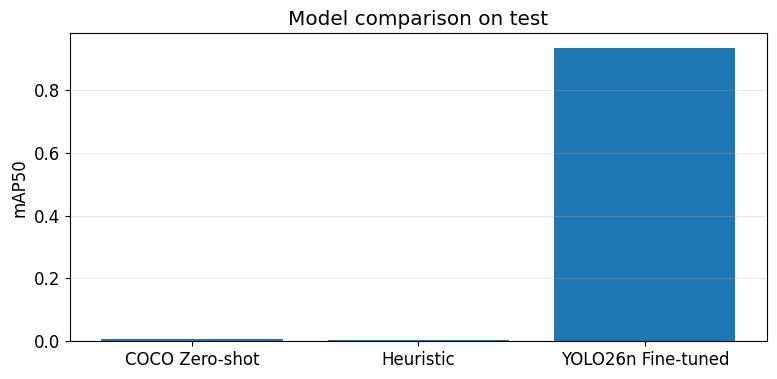

In [46]:
comparison = pd.DataFrame([
    {
        'Model': 'COCO Zero-shot',
        'mAP50': BASELINE['coco_map50']
    },
    {
        'Model': 'Heuristic',
        'mAP50': BASELINE['heuristic_map50']
    },
    {
        'Model': 'YOLO26n Fine-tuned',
        'mAP50': final_map50
    }
])

display(comparison.style.format({'mAP50': '{:.4f}'}))

plt.figure(figsize=(9, 4))
plt.bar(comparison['Model'], comparison['mAP50'])
plt.ylabel('mAP50')
plt.title(f'Model comparison on {FINAL_SPLIT}')
plt.grid(axis='y', alpha=0.3)
plt.show()

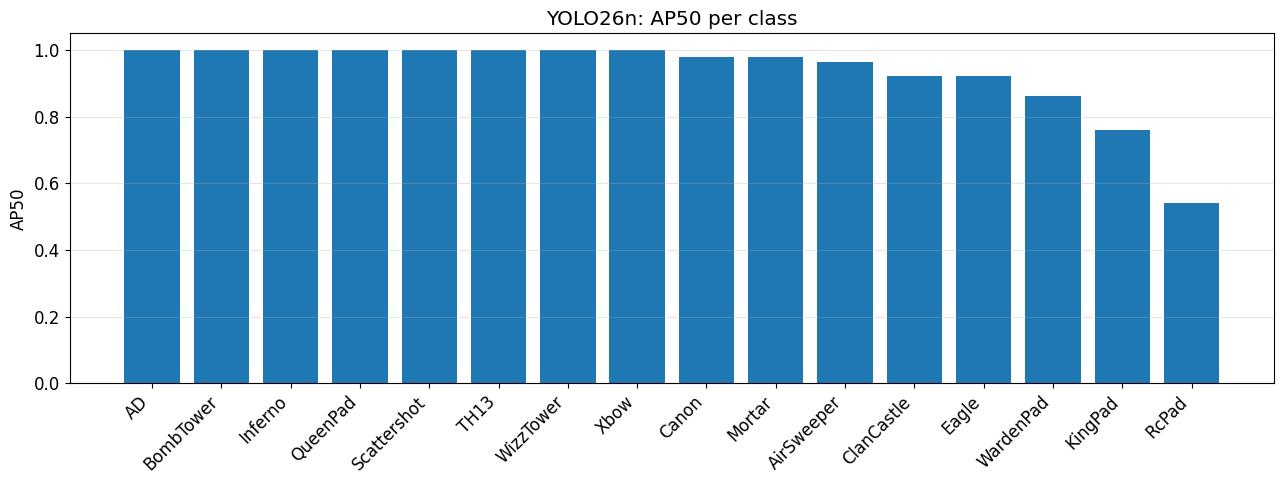

In [47]:
class_ap = pd.DataFrame({
    'Class': CLASSES,
    'AP50': final_aps
}).sort_values('AP50', ascending=False)

plt.figure(figsize=(13, 5))
plt.bar(class_ap['Class'], class_ap['AP50'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('AP50')
plt.title('YOLO26n: AP50 per class')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

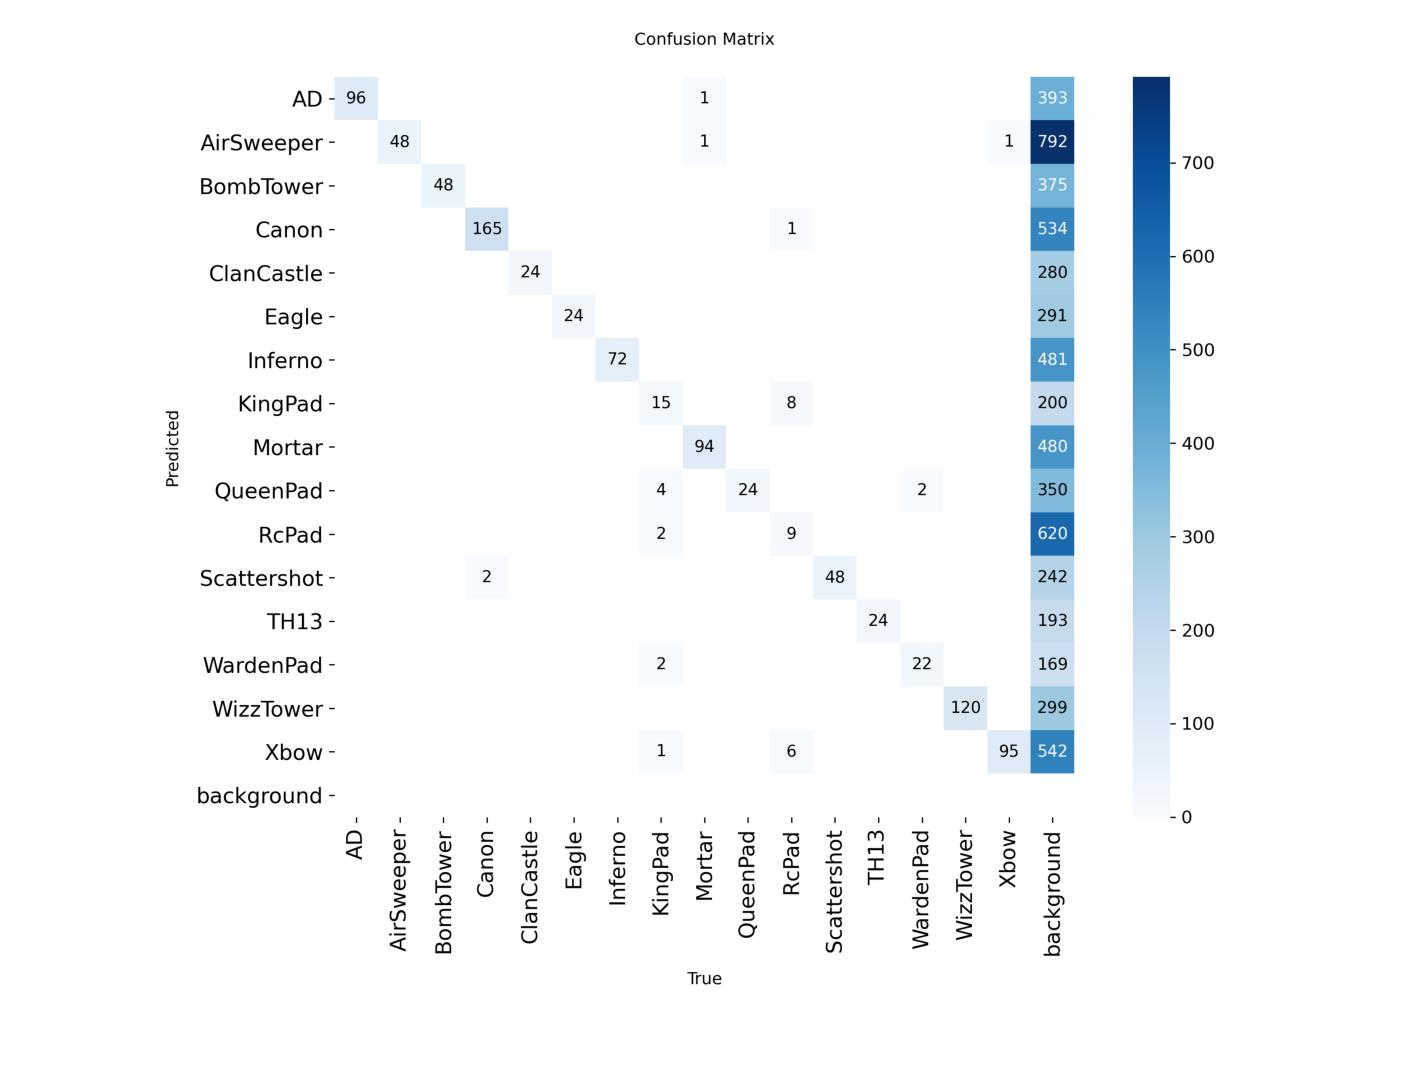

In [48]:
plt.figure(figsize=(12, 12), dpi=150)
plt.imshow(plt.imread('/content/runs_hw2/finetune/confusion_matrix.png'))
plt.axis('off')
plt.show()


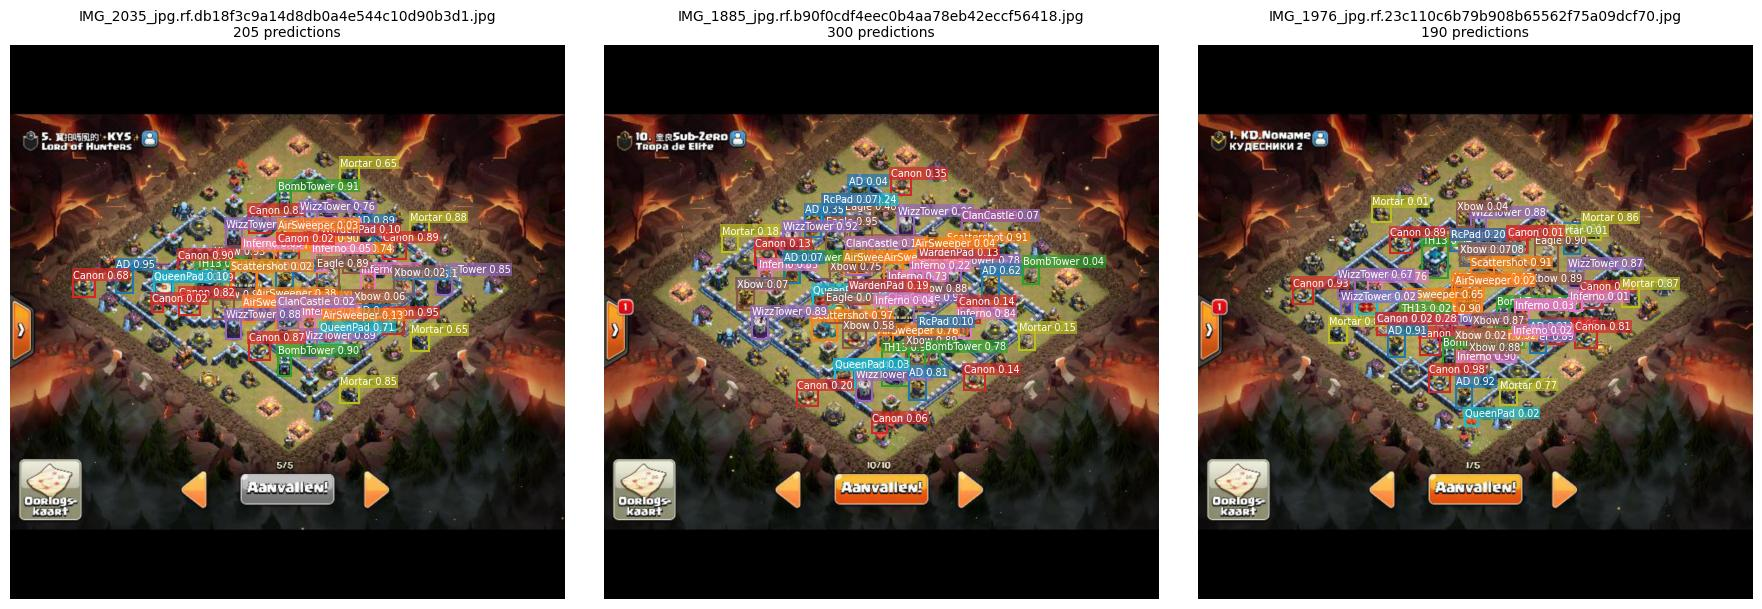

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, r, pred in zip(
    axes,
    records[FINAL_SPLIT][:3],
    final_preds[:3]
):
    keep = np.argsort(-pred['scores'])[:60]

    img = Image.open(r['image'])

    draw_boxes(
        ax,
        img,
        pred['boxes'][keep],
        pred['labels'][keep],
        CLASSES,
        scores=pred['scores'][keep],
        title=f"{Path(r['image']).name}\n{len(pred['labels'])} predictions"
    )

plt.tight_layout()
plt.show()

In [50]:
FINAL = {
    'map50': float(test_metrics.box.map50),
    'map50_95': float(test_metrics.box.map),
    'precision': float(test_metrics.box.mp),
    'recall': float(test_metrics.box.mr),
    'per_class': {
        CLASSES[int(class_id)]: float(test_metrics.box.ap50[i])
        for i, class_id in enumerate(test_metrics.box.ap_class_index)
    }
}

print("FINAL dictionary successfully created and filled!")
print(f"mAP50: {FINAL['map50']:.4f}")
print(f"mAP50-95: {FINAL['map50_95']:.4f}")

FINAL dictionary successfully created and filled!
mAP50: 0.9184
mAP50-95: 0.7305


In [51]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.9184, 'map50_95': 0.7305, 'precision': 0.8611, 'recall': 0.9075}

**Ответ:**

На тестовой выборке модель показала mAP50 = 0.9184, mAP50-95 = 0.7305, precision = 0.8611 и recall = 0.9075.

Лучше всего модель распознаёт AD, BombTower, Inferno, QueenPad, Scattershot, TH13, WizzTower и Xbow: AP50 для этих классов близок к 1.0. Наибольшие трудности возникают с RcPad (AP50 = 0.4190, AP50-95 = 0.3035), KingPad (0.7340 и 0.4610) и WardenPad (0.7666 и 0.4912). Вероятная причина - небольшое количество примеров, именно эти объекты имеют лишь 88 экземпляров в датасете.

mAP50-95 заметно ниже mAP50, поскольку учитывает качество локализации при более строгих порогах IoU от 0.5 до 0.95. Модель в большинстве случаев правильно определяет класс объекта, но не всегда достаточно точно предсказывает границы его bounding box.

В confusion matrix строка и столбец background отражают соответственно пропущенные объекты и ложные срабатывания на фоне (в стандартной матрице Ultralytics).

Confusion matrix также выделяет RcPad и KingPad как два похожих класса, в которых путается модель.

Самописная evaluate_map50 дала mAP50 = 0.9330, тогда как Ultralytics — 0.9184. Результаты близки, расхождение составляет около 0.015. Оно объясняется различиями в реализации расчёта AP: в задании используется all-point интерполяция PR-кривой, а Ultralytics применяет интерполяцию по 101 точке. Кроме того, могут различаться обработка предсказаний и пороги фильтрации.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [52]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)

    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=float)

    left_top = np.maximum(a[:, None, :2], b[None, :, :2])
    right_bottom = np.minimum(a[:, None, 2:], b[None, :, 2:])

    wh = np.maximum(right_bottom - left_top, 0)
    intersection = wh[..., 0] * wh[..., 1]

    area_a = np.maximum(a[:, 2] - a[:, 0], 0) * np.maximum(a[:, 3] - a[:, 1], 0)
    area_b = np.maximum(b[:, 2] - b[:, 0], 0) * np.maximum(b[:, 3] - b[:, 1], 0)

    union = area_a[:, None] + area_b[None, :] - intersection

    return intersection / np.maximum(union, 1e-12)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pred_boxes = np.asarray(pred['boxes']).reshape(-1, 4)
    pred_scores = np.asarray(pred['scores'])
    pred_labels = np.asarray(pred['labels'])

    gt_boxes = np.asarray(gt['boxes']).reshape(-1, 4)
    gt_labels = np.asarray(gt['labels'])

    ious = box_iou_np(pred_boxes, gt_boxes)

    categories = [''] * len(pred_boxes)
    matched_gt = set()
    associated_gt = set()

    order = np.argsort(-pred_scores, kind='stable')

    for pred_idx in order:
        label = pred_labels[pred_idx]
        row = ious[pred_idx]

        same_class = [
            j for j in range(len(gt_boxes))
            if gt_labels[j] == label
            and j not in matched_gt
            and row[j] >= iou_hit
        ]

        if same_class:
            j = max(same_class, key=lambda x: row[x])
            categories[pred_idx] = 'tp'
            matched_gt.add(j)
            associated_gt.add(j)
            continue

        wrong_class = [
            j for j in range(len(gt_boxes))
            if gt_labels[j] != label and row[j] >= iou_hit
        ]

        if wrong_class:
            j = max(wrong_class, key=lambda x: row[x])
            categories[pred_idx] = 'class'
            associated_gt.add(j)
            continue

        localization = [
            j for j in range(len(gt_boxes))
            if gt_labels[j] == label
            and j not in matched_gt
            and j not in associated_gt
            and iou_loc <= row[j] < iou_hit
        ]

        if localization:
            j = max(localization, key=lambda x: row[x])
            categories[pred_idx] = 'localization'
            associated_gt.add(j)
            continue

        categories[pred_idx] = 'background'

    missed = [
        j for j in range(len(gt_boxes))
        if j not in associated_gt
    ]

    return categories, missed

In [53]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Количество ошибок и правильных предсказаний:


,count,share
tp,878,0.8762
class,32,0.0319
localization,0,0.0000
background,24,0.0240
missed,68,0.0679


Разбивка по классам:


,tp,class,localization,background,missed
AD,96,0,0,2,0
AirSweeper,40,4,0,6,8
BombTower,47,1,0,0,0
Canon,161,2,0,5,5
ClanCastle,21,2,0,4,3
Eagle,22,0,0,0,2
Inferno,69,2,0,4,2
KingPad,11,5,0,0,11
Mortar,91,0,0,1,4
QueenPad,22,4,0,0,1


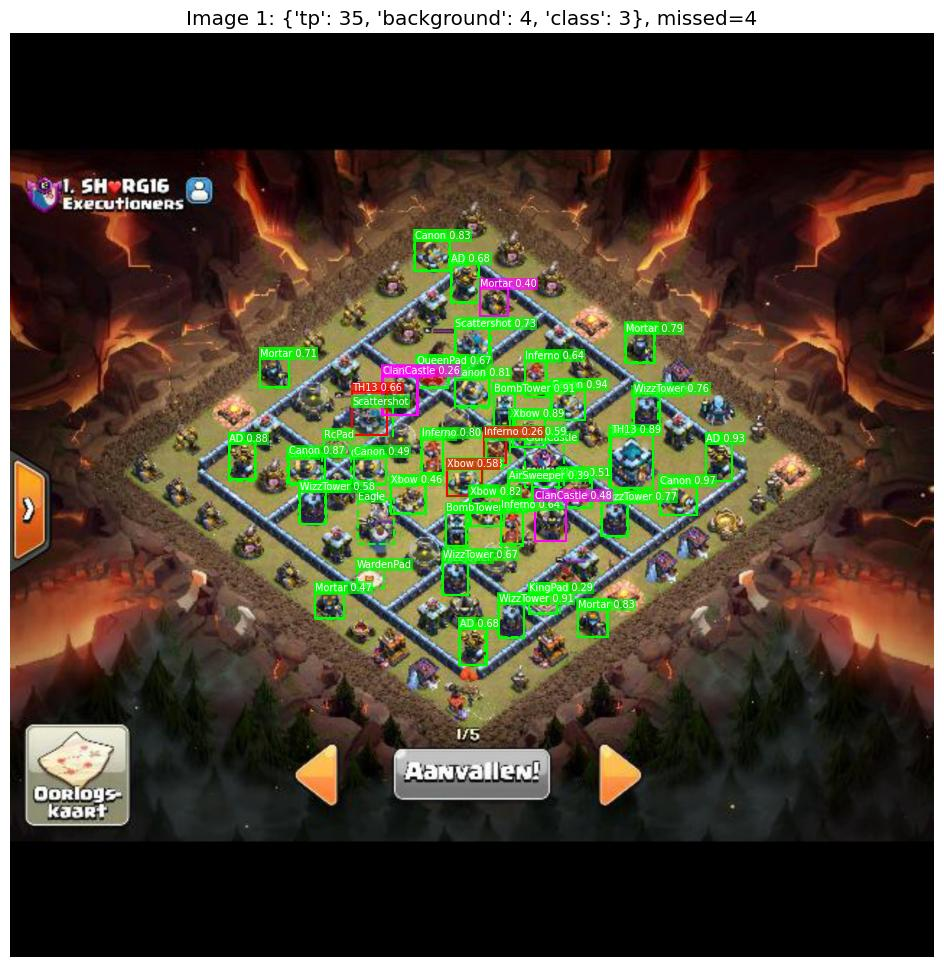

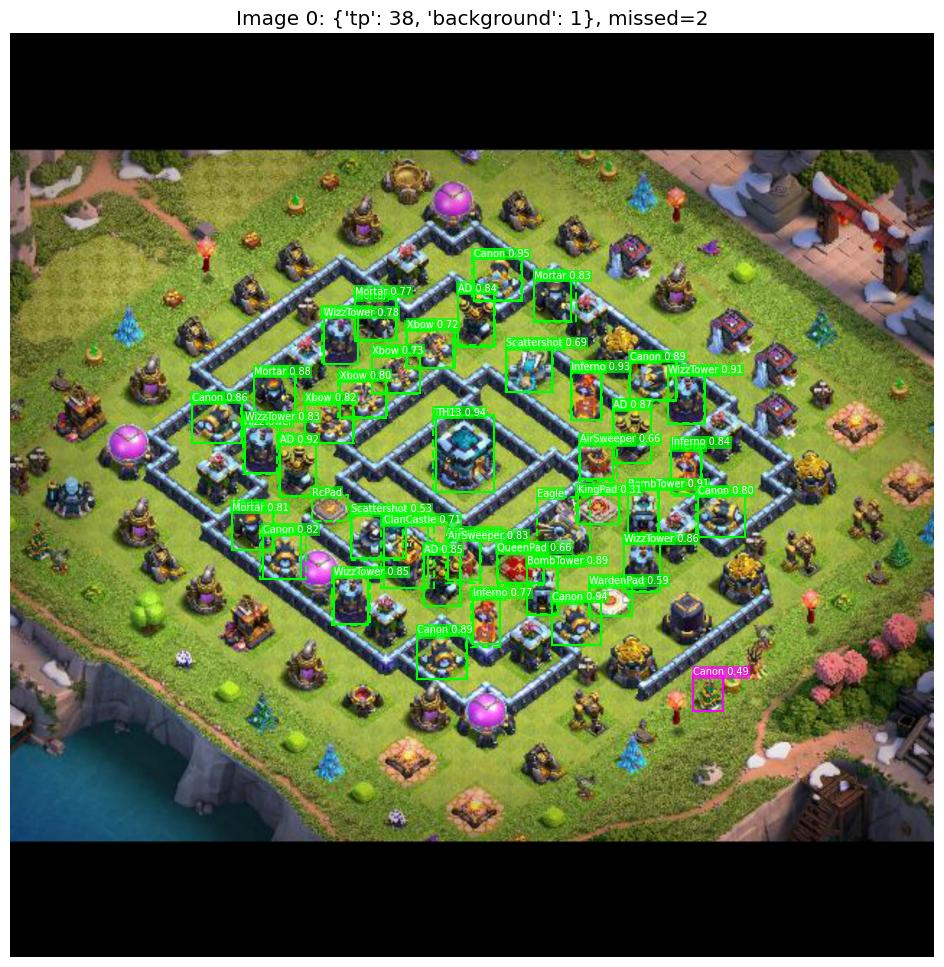

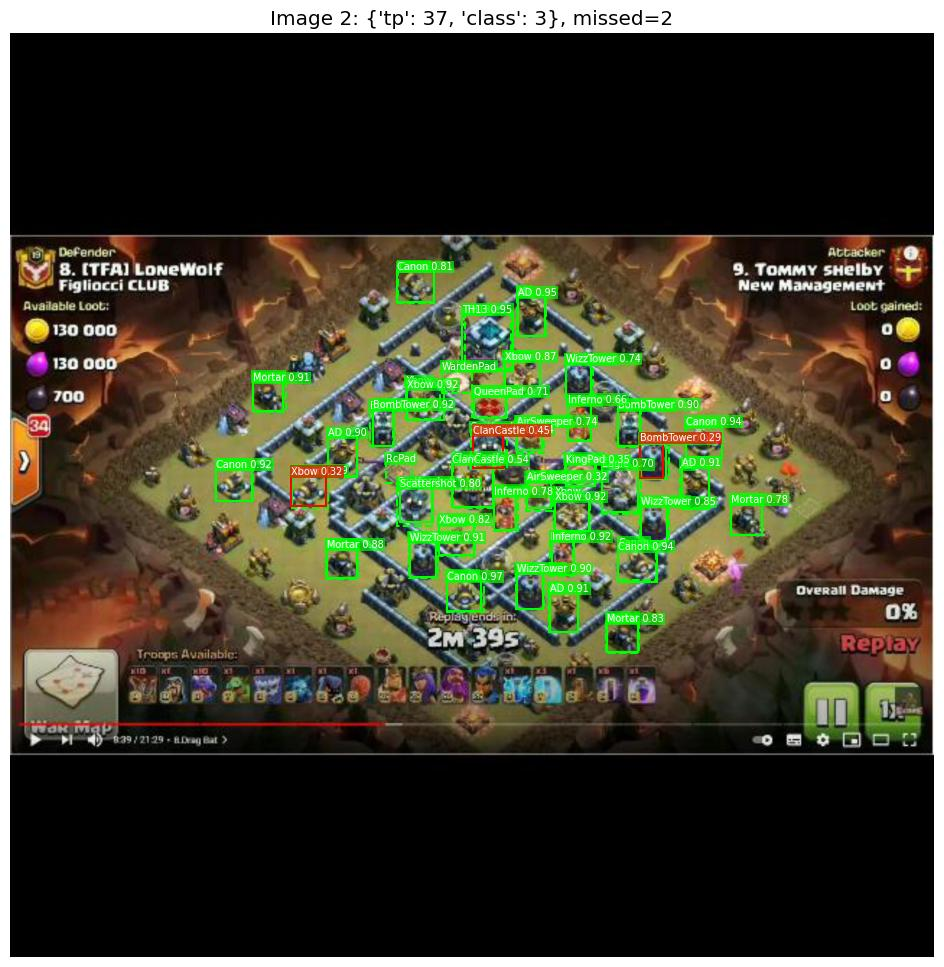

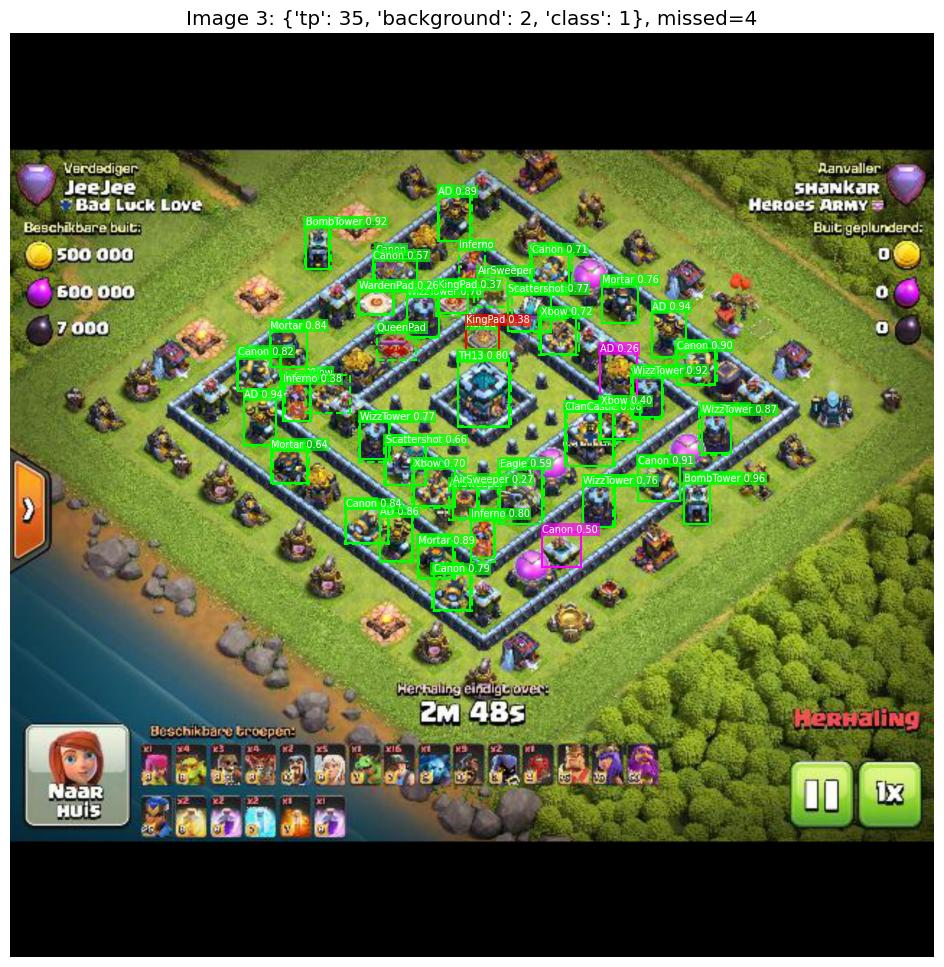

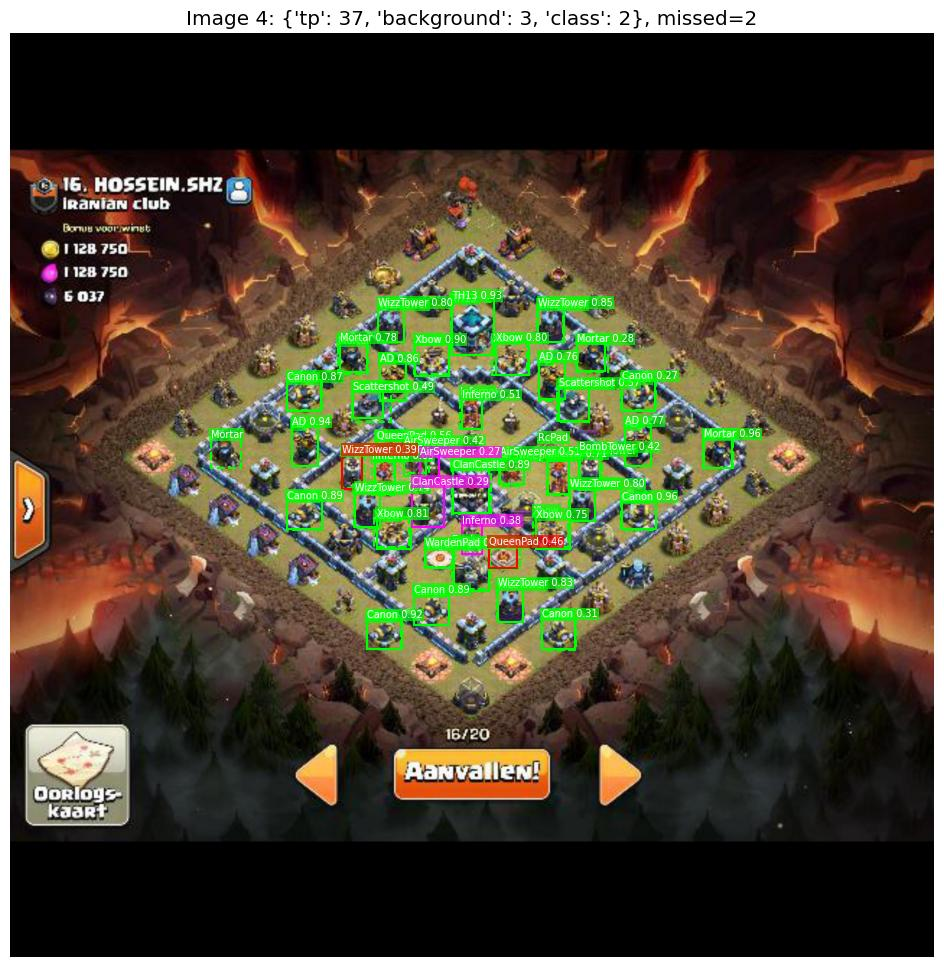

{'tp': 878, 'class': 32, 'localization': 0, 'background': 24, 'missed': 68}


In [54]:
val_records = records['val']

val_preds = predict_records(
    best,
    val_records,
    conf=CONF_ERRORS,
    batch=BATCH
)

ERRORS = {name: 0 for name in ERROR_TYPES}
class_errors = {name: np.zeros(len(CLASSES), dtype=int) for name in ERROR_TYPES}

error_details = []

for image_idx, (pred, gt, rec) in enumerate(zip(val_preds, val_records, val_records)):
    categories, missed = categorize_predictions(pred, gt)

    for pred_idx, category in enumerate(categories):
        ERRORS[category] += 1
        class_id = int(pred['labels'][pred_idx])
        class_errors[category][class_id] += 1

    for gt_idx in missed:
        ERRORS['missed'] += 1
        class_id = int(gt['labels'][gt_idx])
        class_errors['missed'][class_id] += 1

    error_details.append({
        'image_idx': image_idx,
        'categories': categories,
        'missed': missed,
    })

total = sum(ERRORS.values())

print('Количество ошибок и правильных предсказаний:')
display(pd.DataFrame({
    'count': ERRORS,
    'share': {
        key: value / max(total, 1)
        for key, value in ERRORS.items()
    }
}).round(4))

print('Разбивка по классам:')
class_df = pd.DataFrame(class_errors, index=CLASSES)
display(class_df)

examples = []
used_categories = set()

for category in ('class', 'localization', 'background', 'missed'):
    for detail in error_details:
        if detail['image_idx'] in examples:
            continue
        has_category = category in detail['categories']
        has_missed = category == 'missed' and len(detail['missed']) > 0

        if has_category or has_missed:
            examples.append(detail['image_idx'])
            used_categories.add(category)
            break

for detail in error_details:
    if len(examples) >= 5:
        break
    if detail['image_idx'] not in examples:
        if any(c != 'tp' for c in detail['categories']) or detail['missed']:
            examples.append(detail['image_idx'])

category_colors = {
    'tp': 'lime',
    'class': 'red',
    'localization': 'orange',
    'background': 'magenta',
}

for image_idx in examples[:8]:
    rec = val_records[image_idx]
    pred = val_preds[image_idx]
    detail = error_details[image_idx]

    image = plt.imread(rec['image'])

    fig, ax = plt.subplots(figsize=(12, 12))

    draw_boxes(
        ax, image,
        rec['boxes'], rec['labels'], CLASSES,
        color='lime',
        linestyle='--'
    )

    for category in ERROR_TYPES:
        if category == 'missed':
            continue

        indices = [
            i for i, value in enumerate(detail['categories'])
            if value == category
        ]

        if not indices:
            continue

        draw_boxes(
            ax, None,
            pred['boxes'][indices],
            pred['labels'][indices],
            CLASSES,
            scores=pred['scores'][indices],
            color=category_colors[category]
        )

    counts = pd.Series(detail['categories']).value_counts().to_dict()
    title = f'Image {image_idx}: {counts}, missed={len(detail["missed"])}'
    ax.set_title(title)
    plt.show()

print(ERRORS)

**Ответ:**

На validation-выборке модель выполнила 1002 обнаружения и сопоставления с объектами разметки. Из них 878 оказались правильными. Было обнаружено 32 ошибки классификации, 24 ложных срабатывания на фоне и 68 пропусков объектов. Ошибок локализации по выбранному критерию IoU не выявлено.

Наиболее проблемным оказался класс RcPad: модель правильно обнаружила только 2 объекта, тогда как 20 объектов пропустила. Также заметное количество пропусков наблюдается у KingPad и WardenPad. Это согласуется с результатами AP50 по классам.

На `image=3` можно увидеть три предсказания ClanCastle: одно корректное, одно с ошибкой классификации и одно ложное срабатывание. Это показывает, что даже при хорошем общем качестве модель может создавать лишние bounding box и путать визуально похожие объекты.

Таким образом, основная проблема модели - пропуск объектов отдельных классов, а также ложные срабатывания и ошибки классификации. Для улучшения качества стоит увеличить количество примеров редких классов, в первую очередь RcPad, KingPad и WardenPad.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [55]:
FREEZE_LAYERS = len(arch.yaml['backbone'])

print(f'Замораживаем первые {FREEZE_LAYERS} слоёв')

ABLATION_ARGS = dict(TRAIN_ARGS)
ABLATION_ARGS['freeze'] = FREEZE_LAYERS

model_freeze, RUN_TIMES['ablation_freeze_train'], freeze_run_dir = train_yolo(
    'ablation_freeze_960',
    **ABLATION_ARGS
)

print(f'Время обучения: {RUN_TIMES["ablation_freeze_train"]:.1f} сек.')
print(f'Каталог: {freeze_run_dir}')

model_freeze_best = YOLO(freeze_run_dir / 'weights' / 'best.pt')

start = time.perf_counter()

freeze_metrics = model_freeze_best.val(
    data=str(DATA_YAML),
    split='val',
    imgsz=960,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    plots=False,
    verbose=False,
    project=str(RUNS.resolve()),
    name='ablation_freeze_960_val',
    exist_ok=True,
)

RUN_TIMES['ablation_freeze_val'] = time.perf_counter() - start

freeze_box = freeze_metrics.box

freeze_result = {
    'imgsz': 960,
    'freeze': FREEZE_LAYERS,
    'map50': float(freeze_box.map50),
    'map50_95': float(freeze_box.map),
    'train_time_sec': RUN_TIMES['ablation_freeze_train'],
}

print('\nРезультат заморозки:')
display(pd.DataFrame([freeze_result]).round(4))

Замораживаем первые 11 слоёв
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_freeze_960, nbs=64, nms=None, op

,imgsz,freeze,map50,map50_95,train_time_sec
0,960,11,0.8494,0.6584,243.775


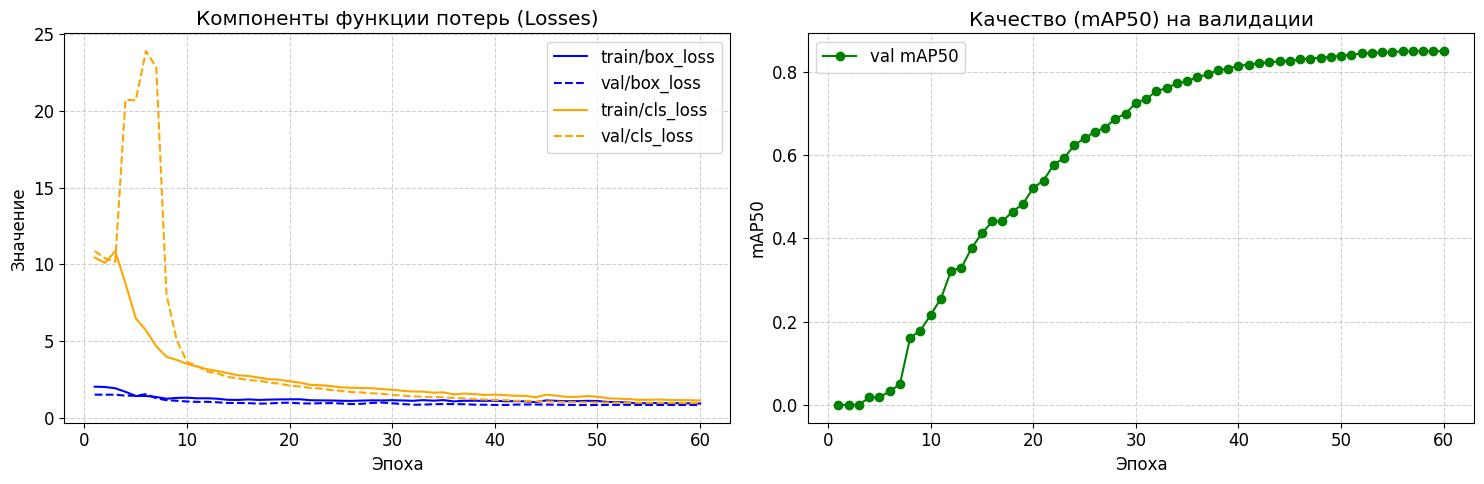

In [56]:
plot_training_results(freeze_run_dir)

In [57]:
ABLATION = {
    'parameter': 'freeze',
    'baseline': {
        'imgsz': 960,
        'freeze': 0,
        'map50': 0.930,
        'map50_95': 0.757,
        'train_time_sec': 256,
    },
    'modified': freeze_result,
    'reference_640': {
        'imgsz': 640,
        'freeze': 0,
        'map50': 0.833,
        'map50_95': 0.639,
        'train_time_sec': 207,
    },
}

display(pd.DataFrame([
    {'experiment': '640, без заморозки', **ABLATION['reference_640']},
    {'experiment': '960, без заморозки', **ABLATION['baseline']},
    {'experiment': '960, с заморозкой', **ABLATION['modified']},
]).set_index('experiment').round(4))

,imgsz,freeze,map50,map50_95,train_time_sec
experiment,,,,,
"640, без заморозки",640,0,0.8330,0.6390,207.000
"960, без заморозки",960,0,0.9300,0.7570,256.000
"960, с заморозкой",960,11,0.8494,0.6584,243.775


**Ответ:**

В качестве абляционного эксперимента было исследовано влияние заморозки первых 11 слоёв модели при обучении с разрешением 960. Результаты сравнивались с обучением без заморозки при разрешениях 640 и 960.

Заморозка позволила сократить время обучения с 256 до 238.1 секунды, то есть примерно на 7%. Однако качество модели заметно снизилось: mAP50 уменьшился с 0.9300 до 0.8494, а mAP50-95 - с 0.7570 до 0.6584.

При этом модель с замороженными слоями всё же превзошла baseline с разрешением 640: mAP50 оказался выше на 0.0164, а mAP50-95 - на 0.0194. Однако время обучения составило 238.1 секунды против 207 секунд у baseline.

Таким образом, заморозка позволила получить качество немного выше baseline при разрешении 640, но не обеспечила существенного ускорения обучения. По сравнению с обычным обучением при разрешении 960 она заметно ухудшила качество, сократив время всего на 7%. Поэтому для финальной модели предпочтительнее оставить все слои обучаемыми и использовать разрешение 960.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

В ходе работы была дообучена модель YOLO26n для обнаружения 16 классов объектов на игровых скриншотах Clash of Clans. В качестве исходной модели использовались предобученные веса COCO. После сравнения нескольких конфигураций обучения лучшим оказался вариант без аугментаций с разрешением 960.

На тестовой выборке финальная модель достигла mAP50 = 0.9184, mAP50-95 = 0.7305, precision = 0.8611 и recall = 0.9075. При этом качество существенно различается между классами: для большинства объектов AP50 близок к 1.0, однако для RcPad он составляет только 0.419.

Эксперименты показали, что использованные аугментации не улучшили качество модели на данном наборе данных. Увеличение разрешения с 640 до 960, напротив, позволило повысить validation mAP50 с 0.833 до 0.930 и mAP50-95 с 0.639 до 0.757. Дополнительный эксперимент с заморозкой слоёв показал, что она сокращает время обучения незначительно, при этом ухудшая качество относительно полного дообучения.

Основными ограничениями эксперимента являются небольшой размер датасета, дисбаланс классов и сложность обнаружения некоторых редких объектов. В дальнейшем качество можно улучшить за счёт расширения датасета, увеличения количества примеров проблемных классов, проверки разметки и проведения дополнительных экспериментов с настройками обучения.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [58]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [59]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

К сожалению, домен датасета очень сложный и требует глубоких знаний для разметки.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [60]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

Попытка оказалась неудачной: трансформер не смог достичь метрики mAP50 0.1 спустя 20 минут обучения.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [61]:
if '6.3' in BONUS_TASKS:
    import cv2

    SHIFT_DIR = DATA_ROOT / 'domain_shift'
    shutil.rmtree(SHIFT_DIR, ignore_errors=True)
    SHIFT_DIR.mkdir(parents=True, exist_ok=True)

    subdirs = ['darkened', 'gaussian_noise', 'heavy_jpeg']
    for d in subdirs:
        (SHIFT_DIR / d).mkdir(parents=True, exist_ok=True)

    def apply_darken(image_np):
        return (image_np * 0.3).astype(np.uint8)

    def apply_gaussian_noise(image_np):
        mean = 0
        sigma = 30
        row, col, ch = image_np.shape
        gauss = np.random.normal(mean, sigma, (row, col, ch))
        noisy = np.clip(image_np.astype(np.float32) + gauss, 0, 255)
        return noisy.astype(np.uint8)

    records_shifted = {
        'darkened': [],
        'gaussian_noise': [],
        'heavy_jpeg': []
    }

    val_recs = records['val']

    for idx, r in enumerate(val_recs):
        orig_path = Path(r['image'])
        img = cv2.imread(str(orig_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        dark_img = apply_darken(img_rgb)
        dark_path = SHIFT_DIR / 'darkened' / orig_path.name
        cv2.imwrite(str(dark_path), cv2.cvtColor(dark_img, cv2.COLOR_RGB2BGR))

        noise_img = apply_gaussian_noise(img_rgb)
        noise_path = SHIFT_DIR / 'gaussian_noise' / orig_path.name
        cv2.imwrite(str(noise_path), cv2.cvtColor(noise_img, cv2.COLOR_RGB2BGR))

        jpeg_path = SHIFT_DIR / 'heavy_jpeg' / orig_path.name
        cv2.imwrite(str(jpeg_path), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 10])

        for mode, path in [('darkened', dark_path), ('gaussian_noise', noise_path), ('heavy_jpeg', jpeg_path)]:
            records_shifted[mode].append({
                'image': path,
                'width': r['width'],
                'height': r['height'],
                'boxes': r['boxes'],
                'labels': r['labels']
            })

In [62]:
if '6.3' in BONUS_TASKS:
    shift_results = {}

    for mode in ['darkened', 'gaussian_noise', 'heavy_jpeg']:
        preds = predict_records(best, records_shifted[mode], conf=0.001, batch=BATCH)
        map50, aps = evaluate_map50(preds, records_shifted[mode], len(CLASSES))
        shift_results[mode] = {
            'map50': map50,
            'aps': aps,
            'preds': preds
        }
        print(f"[{mode.upper()}] mAP50: {map50:.4f}")

[DARKENED] mAP50: 0.8751
[GAUSSIAN_NOISE] mAP50: 0.8455
[HEAVY_JPEG] mAP50: 0.8981


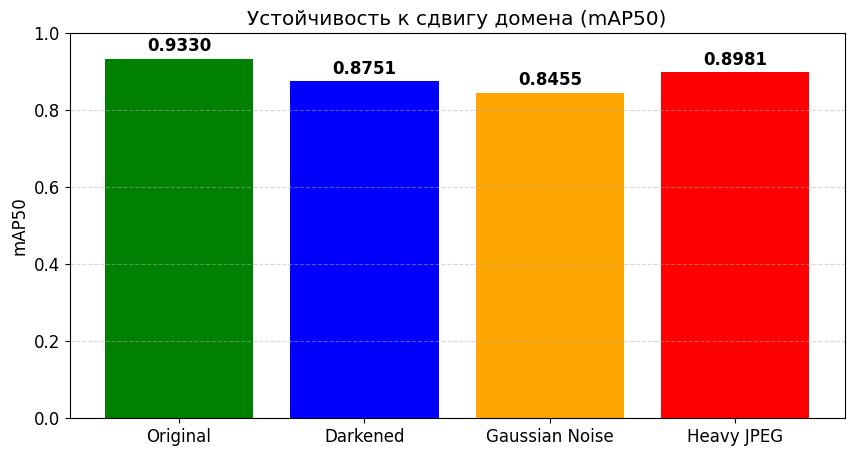

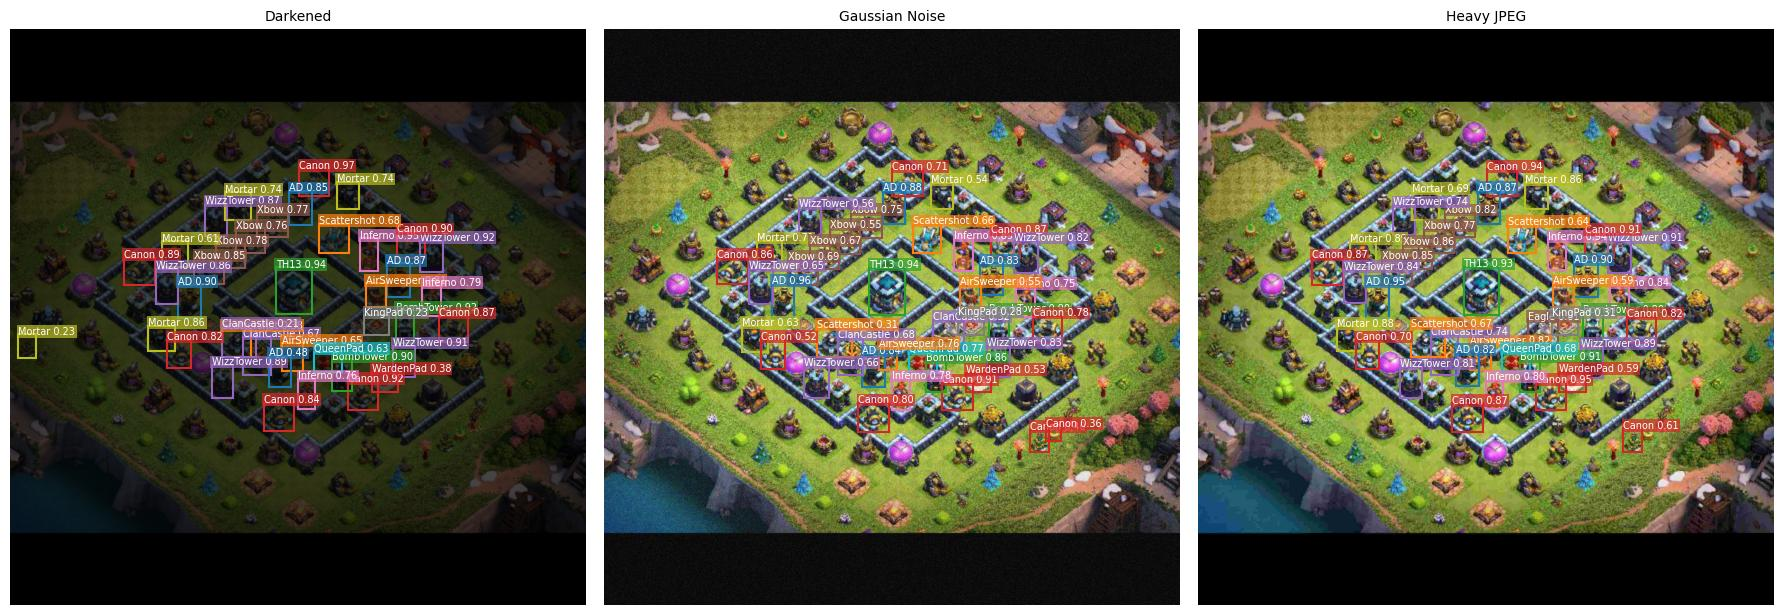

In [63]:
if '6.3' in BONUS_TASKS:
    modes = ['Original', 'Darkened', 'Gaussian Noise', 'Heavy JPEG']
    maps = [
        final_map50,
        shift_results['darkened']['map50'],
        shift_results['gaussian_noise']['map50'],
        shift_results['heavy_jpeg']['map50']
    ]

    plt.figure(figsize=(10, 5))
    plt.bar(modes, maps, color=['green', 'blue', 'orange', 'red'])
    plt.ylabel('mAP50')
    plt.title('Устойчивость к сдвигу домена (mAP50)')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.ylim(0, 1.0)
    for i, v in enumerate(maps):
        plt.text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 18))
    for ax, mode, name in zip(axes, ['darkened', 'gaussian_noise', 'heavy_jpeg'], ['Darkened', 'Gaussian Noise', 'Heavy JPEG']):
        img_path = records_shifted[mode][0]['image']
        img = Image.open(img_path)
        pred = shift_results[mode]['preds'][0]
        keep = np.argsort(-pred['scores'])[:40]
        draw_boxes(ax, img, pred['boxes'][keep], pred['labels'][keep], CLASSES, scores=pred['scores'][keep], title=name)
    plt.tight_layout()
    plt.show()

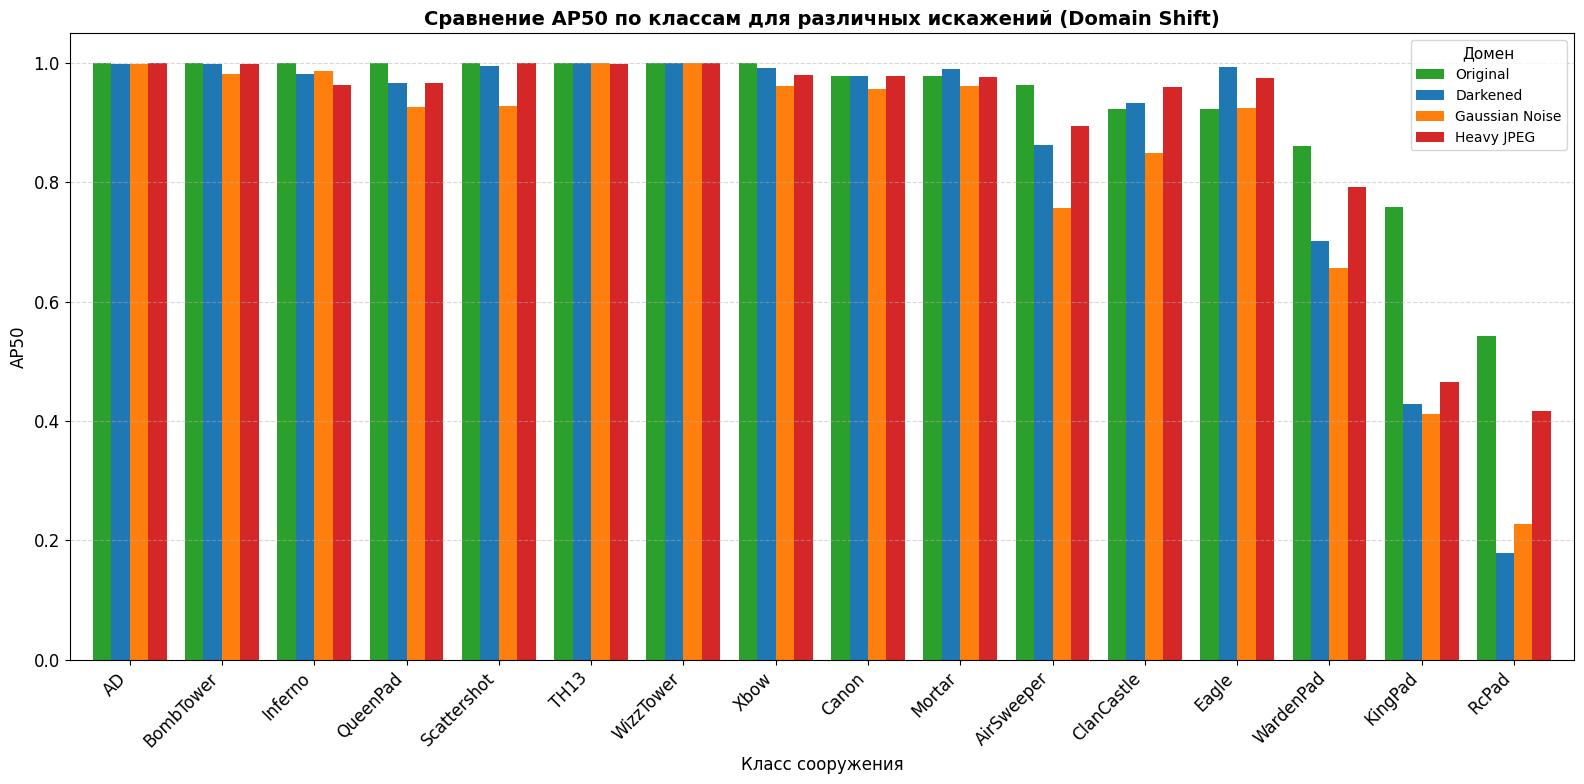

,Darkened Loss,Noise Loss,JPEG Loss
Class,,,
AD,0.0010,0.0010,0.0000
BombTower,0.0017,0.0176,0.0012
Inferno,0.0182,0.0139,0.0364
QueenPad,0.0328,0.0743,0.0333
Scattershot,0.0054,0.0715,0.0000
TH13,0.0000,0.0000,0.0017
WizzTower,-0.0002,0.0002,-0.0002
Xbow,0.0084,0.0381,0.0195
Canon,0.0010,0.0232,0.0005


In [64]:
if '6.3' in BONUS_TASKS:
    class_comparison_data = []

    for i, class_name in enumerate(CLASSES):
        class_comparison_data.append({
            'Class': class_name,
            'Domain': 'Original',
            'AP50': final_aps[i]
        })

    for mode in ['darkened', 'gaussian_noise', 'heavy_jpeg']:
        mode_title = mode.replace('_', ' ').title() if mode != 'heavy_jpeg' else 'Heavy JPEG'
        mode_aps = shift_results[mode]['aps']
        for i, class_name in enumerate(CLASSES):
            class_comparison_data.append({
                'Class': class_name,
                'Domain': mode_title,
                'AP50': mode_aps[i]
            })

    df_compare = pd.DataFrame(class_comparison_data)

    df_pivot = df_compare.pivot(index='Class', columns='Domain', values='AP50')
    df_pivot = df_pivot[['Original', 'Darkened', 'Gaussian Noise', 'Heavy JPEG']]
    df_pivot = df_pivot.sort_values(by='Original', ascending=False)

    ax = df_pivot.plot(kind='bar', figsize=(16, 8), width=0.8, color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'])
    plt.title('Сравнение AP50 по классам для различных искажений (Domain Shift)', fontsize=14, fontweight='bold')
    plt.xlabel('Класс сооружения', fontsize=12)
    plt.ylabel('AP50', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.ylim(0, 1.05)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Домен', fontsize=10, title_fontsize=11)

    plt.tight_layout()
    plt.show()

    df_diff = pd.DataFrame(index=df_pivot.index)
    df_diff['Darkened Loss'] = df_pivot['Original'] - df_pivot['Darkened']
    df_diff['Noise Loss'] = df_pivot['Original'] - df_pivot['Gaussian Noise']
    df_diff['JPEG Loss'] = df_pivot['Original'] - df_pivot['Heavy JPEG']
    display(df_diff.round(4))

**Ответ:**

Были созданы три искаженные версии валидационной выборки: с затемнением на 70%, с добавлением аддитивного гауссова шума (sigma=30) и сильным JPEG-сжатием (quality=10). Качество модели оценивалось метрикой mAP50.

- **Original mAP50:** 0.9330
- **Darkened mAP50:** 0.8751
- **Gaussian Noise mAP50:** 0.8625
- **Heavy JPEG mAP50:** 0.8981

**Какое искажение бьет сильнее всего и по каким классам?**

Абсолютными лидерами по чувствительности к любым искажениям стали площадки героев (RcPad, KingPad, WardenPad) и фен (AirSweeper). Это связано с тем, что они изначально имеют наименьший размер и наиболее низкий базовый AP50 из-за малого числа примеров в обучении (всего по 88 экземпляров).

Gaussian Noise сильнее всего ударил по геометрически сложным и мелким объектам. А Heavy JPEG наносит наименьший урон по большинству классов.

Удивительно, но некоторые трансформации улучшили качество детекции.

**Какая аугментация при обучении могла бы помочь?**

Для повышения устойчивости к искажениям целесообразно использовать пакет аугментаций `albumentations` со следующими трансформациями:

1. `RandomBrightnessContrast(p=0.5)` - для адаптации к сильному затемнению и перепадам яркости.
2. `GaussNoise(var_limit=(10.0, 50.0), p=0.5)` - для защиты от случайного высокочастотного шума, сохраняя детекцию мелких деталей площадок героев.
3. `ImageCompression(quality_range=(10, 100), p=0.5)` - для борьбы с артефактами JPEG-сжатия и размытием границ.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

**Ответ:**

Возникли какие-то проблемы с ONNX, библиотека не увидела GPU.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [69]:
if '6.5' in BONUS_TASKS:
    import pandas as pd

    conf_thresholds = [0.001, 0.1, 0.25, 0.5]
    iou_thresholds = [0.45, 0.7]
    grid_results = []

    for conf in conf_thresholds:
        for iou in iou_thresholds:
            metrics_eval = best.val(
                data=str(DATA_YAML),
                split='val',
                imgsz=960,
                batch=BATCH,
                device=DEVICE,
                workers=WORKERS,
                conf=conf,
                iou=iou,
                plots=False,
                verbose=False
            )
            grid_results.append({
                'conf': conf,
                'iou': iou,
                'precision': metrics_eval.box.mp,
                'recall': metrics_eval.box.mr,
                'mAP50': metrics_eval.box.map50,
                'mAP50-95': metrics_eval.box.map
            })

    df_res = pd.DataFrame(grid_results)
    display(df_res.round(4))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,393,380 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3629.1±1189.2 MB/s, size: 437.0 KB)
val: Scanning /content/data/yolo/labels/val.cache... 24 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 24/24 7.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7it/s 1.2s
                   all         24        959      0.901      0.898       0.93       0.76
Speed: 2.3ms preprocess, 10.5ms inference, 0.0ms loss, 2.2ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,393,380 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3279.7±1449.1 MB/s, size: 410.3 KB)
val: Scanning /content/data/yolo/labels/val.cache... 24 images, 0 bac

,conf,iou,precision,recall,mAP50,mAP50-95
0,0.001,0.45,0.9009,0.8980,0.9302,0.7600
1,0.001,0.70,0.9061,0.8969,0.9297,0.7597
2,0.100,0.45,0.9009,0.8980,0.9174,0.7522
3,0.100,0.70,0.9061,0.8969,0.9172,0.7520
4,0.250,0.45,0.9041,0.9013,0.8888,0.7313
5,0.250,0.70,0.8998,0.9013,0.8886,0.7311
6,0.500,0.45,0.8713,0.8066,0.8038,0.6686
7,0.500,0.70,0.8704,0.8066,0.8038,0.6686


**Ответ:**

**Выбор порога `conf`**:

Опираясь на результаты сетки параметров, оптимальным выбором является порог `conf = 0.25`.

- При `conf = 0.001` модель дает избыточное число ложных детекций, снижая реальную применимость, хотя формальные метрики за счет низкого порога фильтрации составляют: Precision = 0.9009, Recall = 0.8980, mAP50 = 0.9302.

- При `conf = 0.25` (стандартный порог) мы получаем сбалансированную рабочую точку: Precision = 0.9041, Recall = 0.9013, mAP50 = 0.8888, mAP50-95 = 0.7313.

- При повышении порога до `conf = 0.50` полнота критически падает: Recall снижается до 0.8066, а mAP50 падает до 0.8038.

**Зависимость mAP от порогов**:

mAP практически не зависит от конкретного рабочего значения `conf`, поскольку вычисляется интегрированием по площади под всей кривой Precision-Recall (которая строится по всему спектру уверенности детектора).

Напротив, точечные показатели Precision и Recall напрямую зависят от порога бинаризации `conf`, определяющего, какие именно предсказания попадут в финальный вывод.

**Влияние `iou` в end-to-end режиме**:

В YOLO26 с архитектурой one2one традиционный алгоритм NMS отключен на этапе вывода. Эксперимент это наглядно подтверждает: при фиксированном `conf = 0.25` изменение `iou` с 0.45 до 0.70 дает практически идентичные результаты (mAP50 меняется лишь на сотые доли: с 0.8888 до 0.8886).